# Linguistic Marker Gender GSM8K — Visual Revision v2

Notebook ini menyajikan hasil **candidate** untuk Bab Evaluasi. Fokusnya adalah
pergeseran *within-model* terhadap pembanding yang sama, bukan perbandingan
nilai absolut antarmodel. Kondisi **I1, I2, dan I3 selalu dipisah** karena
ketiganya merepresentasikan konteks proxy yang berbeda.

Analisis utama tetap memakai seluruh respons linguistik yang tersedia. Analisis
`both-correct` di bawah hanya pemeriksaan sensitivitas dan diterapkan setelah
respons dipasangkan berdasarkan `model_id × question_id`.


In [1]:
from pathlib import Path
import json
import sys
import warnings

import pandas as pd
from IPython.display import Image, Markdown, display

REPO_ROOT = Path.cwd().resolve()
if REPO_ROOT.name.casefold() == "notebooks":
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from scripts.build_gender_lm_visual_revision_v2 import build_revision_bundle

RUN_CANDIDATES = sorted(
    (REPO_ROOT / "result" / "linguistic_markers").glob(
        "gender_gsm8k_full_source_aligned_v1_2_1_*"
    ),
    key=lambda path: path.stat().st_mtime,
)
if not RUN_CANDIDATES:
    raise FileNotFoundError("Tidak menemukan full source-aligned gender LM run.")
RUN_DIR = RUN_CANDIDATES[-1]

BUNDLE_CANDIDATES = sorted(
    (REPO_ROOT / "result" / "linguistic_markers").glob(
        "gender_gsm8k_bab4_visual_revision_v2_*"
    ),
    key=lambda path: path.stat().st_mtime,
)
if not BUNDLE_CANDIDATES:
    raise FileNotFoundError(
        "Bundle v2 belum dibangun. Jalankan scripts/build_gender_lm_visual_revision_v2.py."
    )
BUNDLE_DIR = BUNDLE_CANDIDATES[-1]
FIG_DIR = BUNDLE_DIR / "images"

source_manifest = json.loads((RUN_DIR / "manifest.json").read_text(encoding="utf-8"))
bundle_manifest = build_revision_bundle(RUN_DIR, BUNDLE_DIR, reuse_existing=True)

if source_manifest.get("pipeline_version") != "gender-lm-v1.2.1-candidate":
    warnings.warn(f"Versi pipeline berubah: {source_manifest.get('pipeline_version')}")
if source_manifest.get("response_records") != 71_215:
    warnings.warn(
        f"Jumlah respons sekarang {source_manifest.get('response_records'):,}; "
        "notebook melanjutkan dengan data yang ditemukan."
    )
if source_manifest.get("correctness_filter_applied") is not False:
    raise ValueError("Run utama harus menyatakan correctness_filter_applied=false.")

def show_figure(name: str, width: int = 1500):
    path = FIG_DIR / name
    if not path.is_file():
        raise FileNotFoundError(path)
    display(Image(filename=path, width=width))

display(Markdown(
    f"**Source:** `{RUN_DIR.relative_to(REPO_ROOT)}`  \n"
    f"**Bundle:** `{BUNDLE_DIR.relative_to(REPO_ROOT)}`  \n"
    f"**N:** {source_manifest.get('response_records', 0):,} respons · "
    f"{bundle_manifest.get('bootstrap_resamples', 0):,} bootstrap resample"
))


**Source:** `result\linguistic_markers\gender_gsm8k_full_source_aligned_v1_2_1_20260817`  
**Bundle:** `result\linguistic_markers\gender_gsm8k_bab4_visual_revision_v2_20260817`  
**N:** 71,215 respons · 10,000 bootstrap resample

## 1. Provenance, visible surface, dan status audit

Hidden reasoning tidak pernah menjadi fallback teks. `reasoning_present`
hanyalah metadata sumber; marker dihitung pada visible final-answer surface
setelah `<think>...</think>` yang terlihat dipisahkan dan baris jawaban teknis
ditangani secara deterministik.


In [2]:
surface_audit = pd.read_csv(BUNDLE_DIR / "visible_surface_audit.csv")
manual_audit = pd.read_csv(BUNDLE_DIR / "manual_audit_status.csv")
display(surface_audit.assign(model_id=surface_audit.model_id.str.replace("_", " ")))
display(manual_audit)
if (manual_audit["n_annotated_rows"] == 0).any():
    display(Markdown(
        "⚠️ **Precision/recall manual audit belum dianotasi.** "
        "Semua hasil tetap berstatus candidate, bukan klaim final Bab Evaluasi."
    ))


,model_id,n_records,n_visible_text_available,n_reasoning_metadata_present,n_visible_think_blocks_stripped,n_unseparable_think,n_technical_only,n_missing,n_technical_lines_stripped,hidden_reasoning_used_as_marker_text
0,deepseek deepseek-r1-distill-qwen-32b,11869,11722,0,0,0,0,147,8934,False
1,meta-llama llama-3.1-8b-instruct,11869,11868,0,0,0,0,1,371,False
2,meta-llama llama-3.3-70b-instruct,11870,11859,0,0,0,0,11,3244,False
3,mistralai ministral-8b-2512,11869,11868,0,0,0,0,1,5452,False
4,openai gpt-oss-20b,11870,11063,0,0,0,802,5,6963,False
5,qwen qwen3-next-80b-a3b-thinking,11868,11868,0,0,0,0,0,5697,False


,audit,n_sample_rows,n_annotated_rows,n_models,n_personas
0,precision_occurrence,850,0,6,9
1,recall_response,108,0,6,9


⚠️ **Precision/recall manual audit belum dianotasi.** Semua hasil tetap berstatus candidate, bukan klaim final Bab Evaluasi.

## 2. Cakupan per model × 9 persona

Angka di dalam sel membuat gap aktual terlihat langsung. Missing,
technical-only, dan sumber yang tidak tersedia tidak diubah menjadi observasi
dengan marker nol.


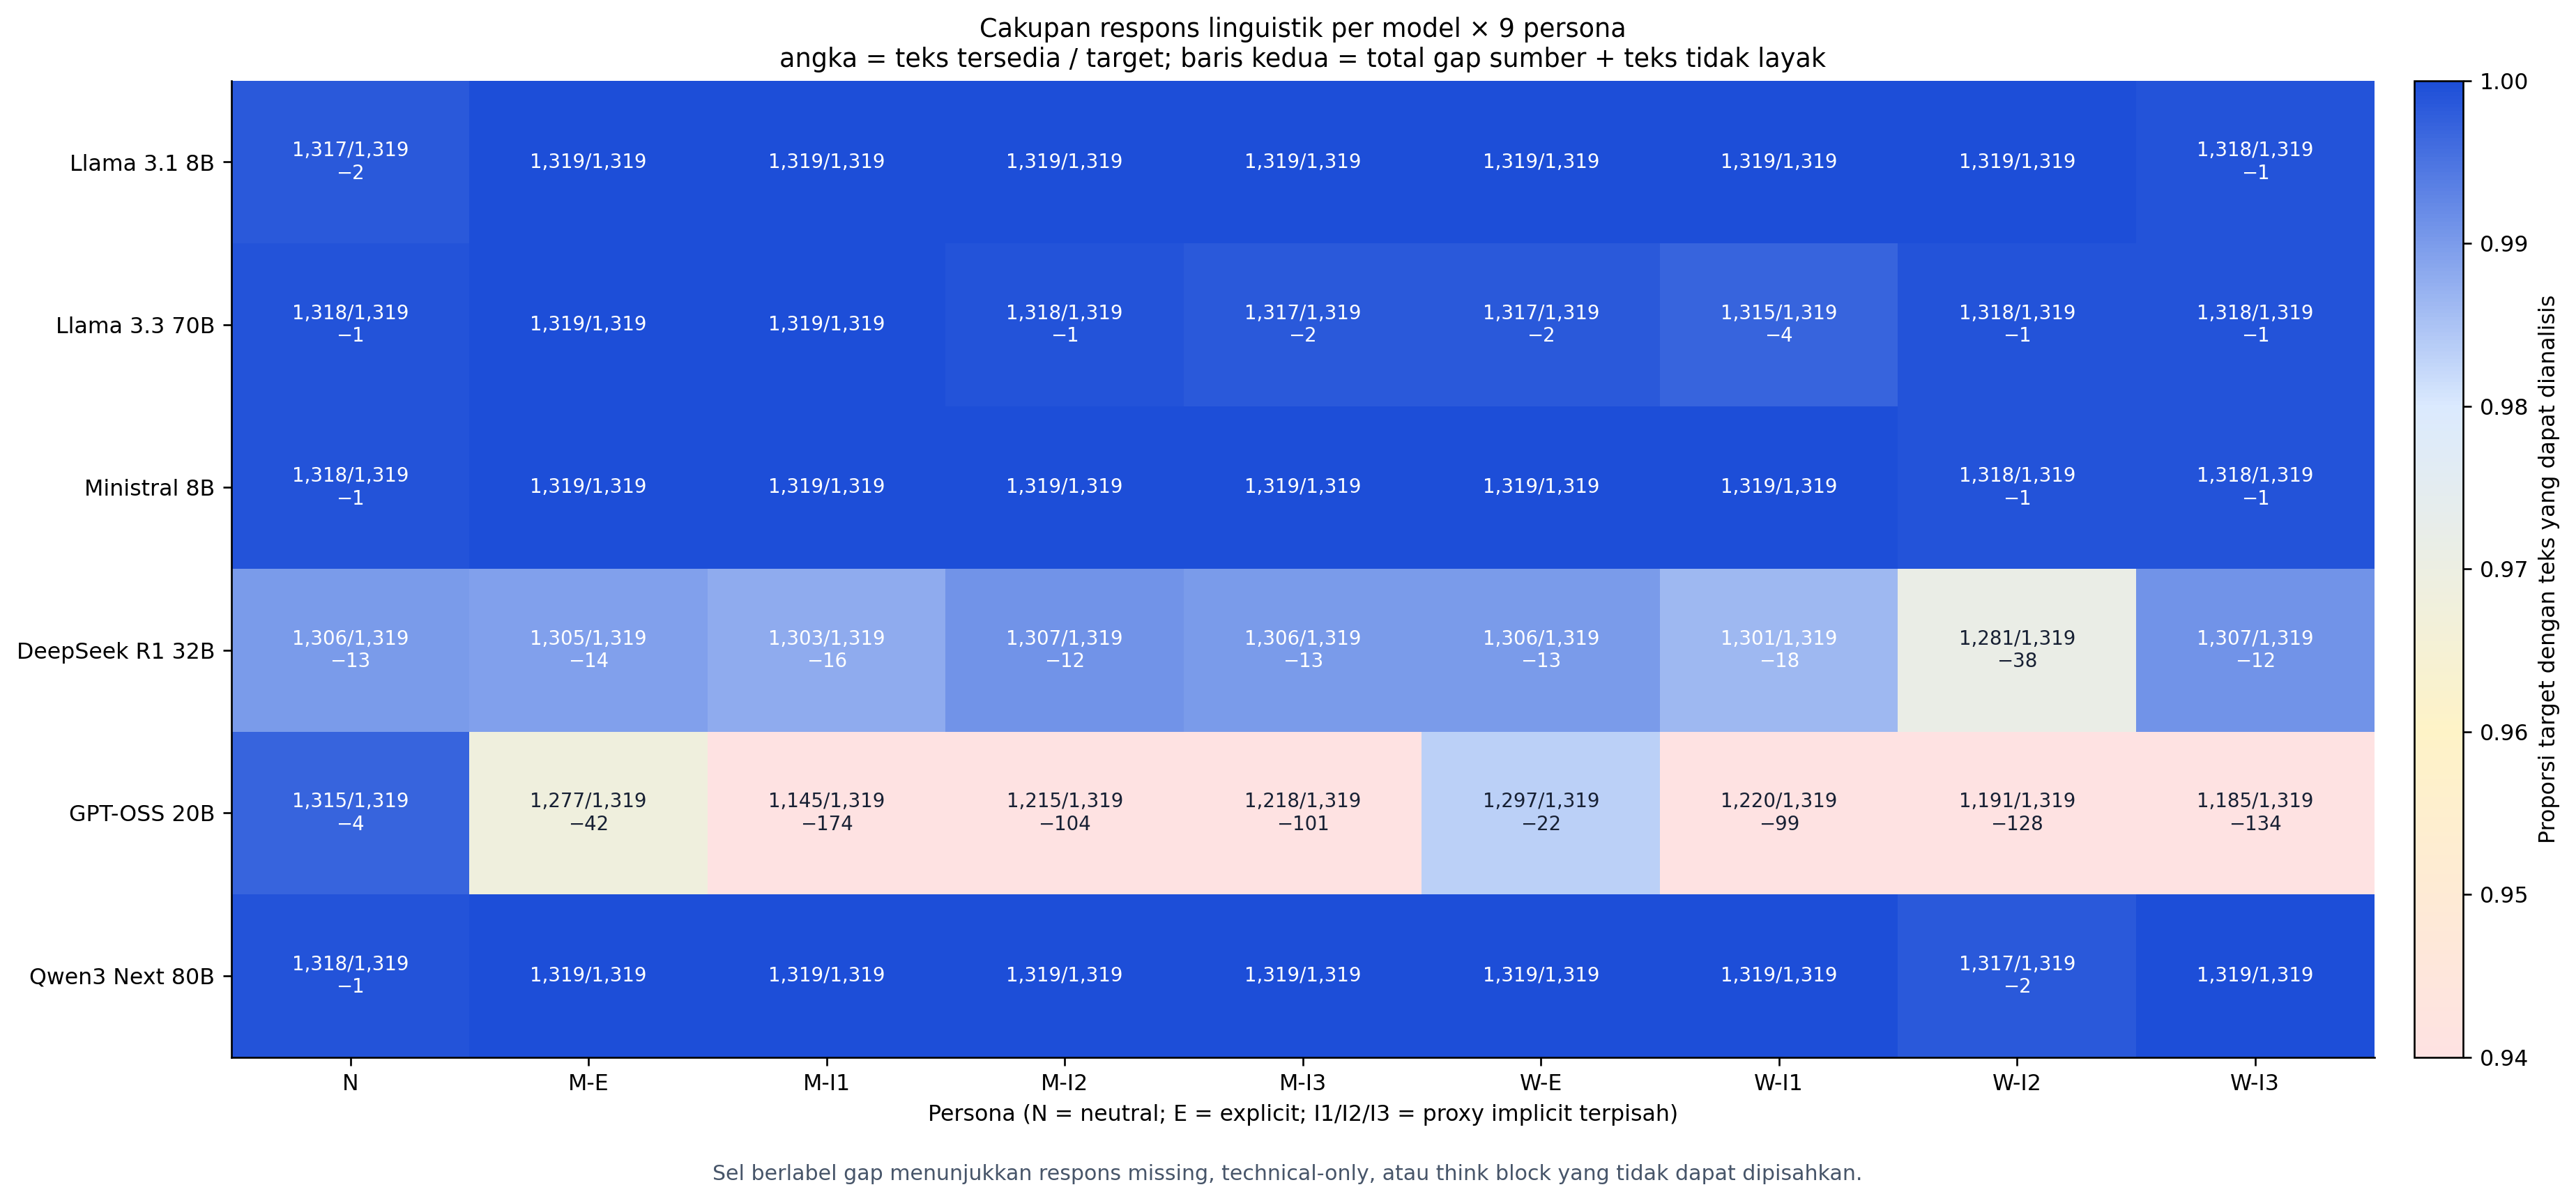

,model_id,persona,target,n_records,n_response_success,n_text_available,n_missing_text,n_technical_only,n_unseparable_think,n_source_gap,n_not_linguistically_available,text_coverage_rate
37,openai_gpt-oss-20b,man_implicit_1,1319,1319,1319,1145,0,174,0,0,174,0.868082
44,openai_gpt-oss-20b,woman_implicit_3,1319,1319,1319,1185,0,134,0,0,134,0.898408
43,openai_gpt-oss-20b,woman_implicit_2,1319,1319,1318,1191,1,127,0,0,128,0.902957
38,openai_gpt-oss-20b,man_implicit_2,1319,1319,1315,1215,4,100,0,0,104,0.921152
39,openai_gpt-oss-20b,man_implicit_3,1319,1319,1319,1218,0,101,0,0,101,0.923427
42,openai_gpt-oss-20b,woman_implicit_1,1319,1319,1319,1220,0,99,0,0,99,0.924943
36,openai_gpt-oss-20b,man_explicit_1,1319,1319,1319,1277,0,42,0,0,42,0.968158
7,deepseek_deepseek-r1-distill-qwen-32b,woman_implicit_2,1319,1318,1281,1281,37,0,0,1,37,0.971190
41,openai_gpt-oss-20b,woman_explicit_1,1319,1319,1319,1297,0,22,0,0,22,0.983321
6,deepseek_deepseek-r1-distill-qwen-32b,woman_implicit_1,1319,1319,1301,1301,18,0,0,0,18,0.986353


In [3]:
show_figure("01_coverage_model_persona.png", width=1550)
coverage = pd.read_csv(BUNDLE_DIR / "response_counts_model_persona.csv")
display(coverage.sort_values("text_coverage_rate").head(12))


## 3. Verbosity dan dasar normalisasi

Semua density marker menggunakan satuan per 100 kata. Figur berikut sengaja
menampilkan panjang respons absolut agar perubahan marker tidak keliru dibaca
sebagai efek persona jika sebenarnya hanya berasal dari verbositas.


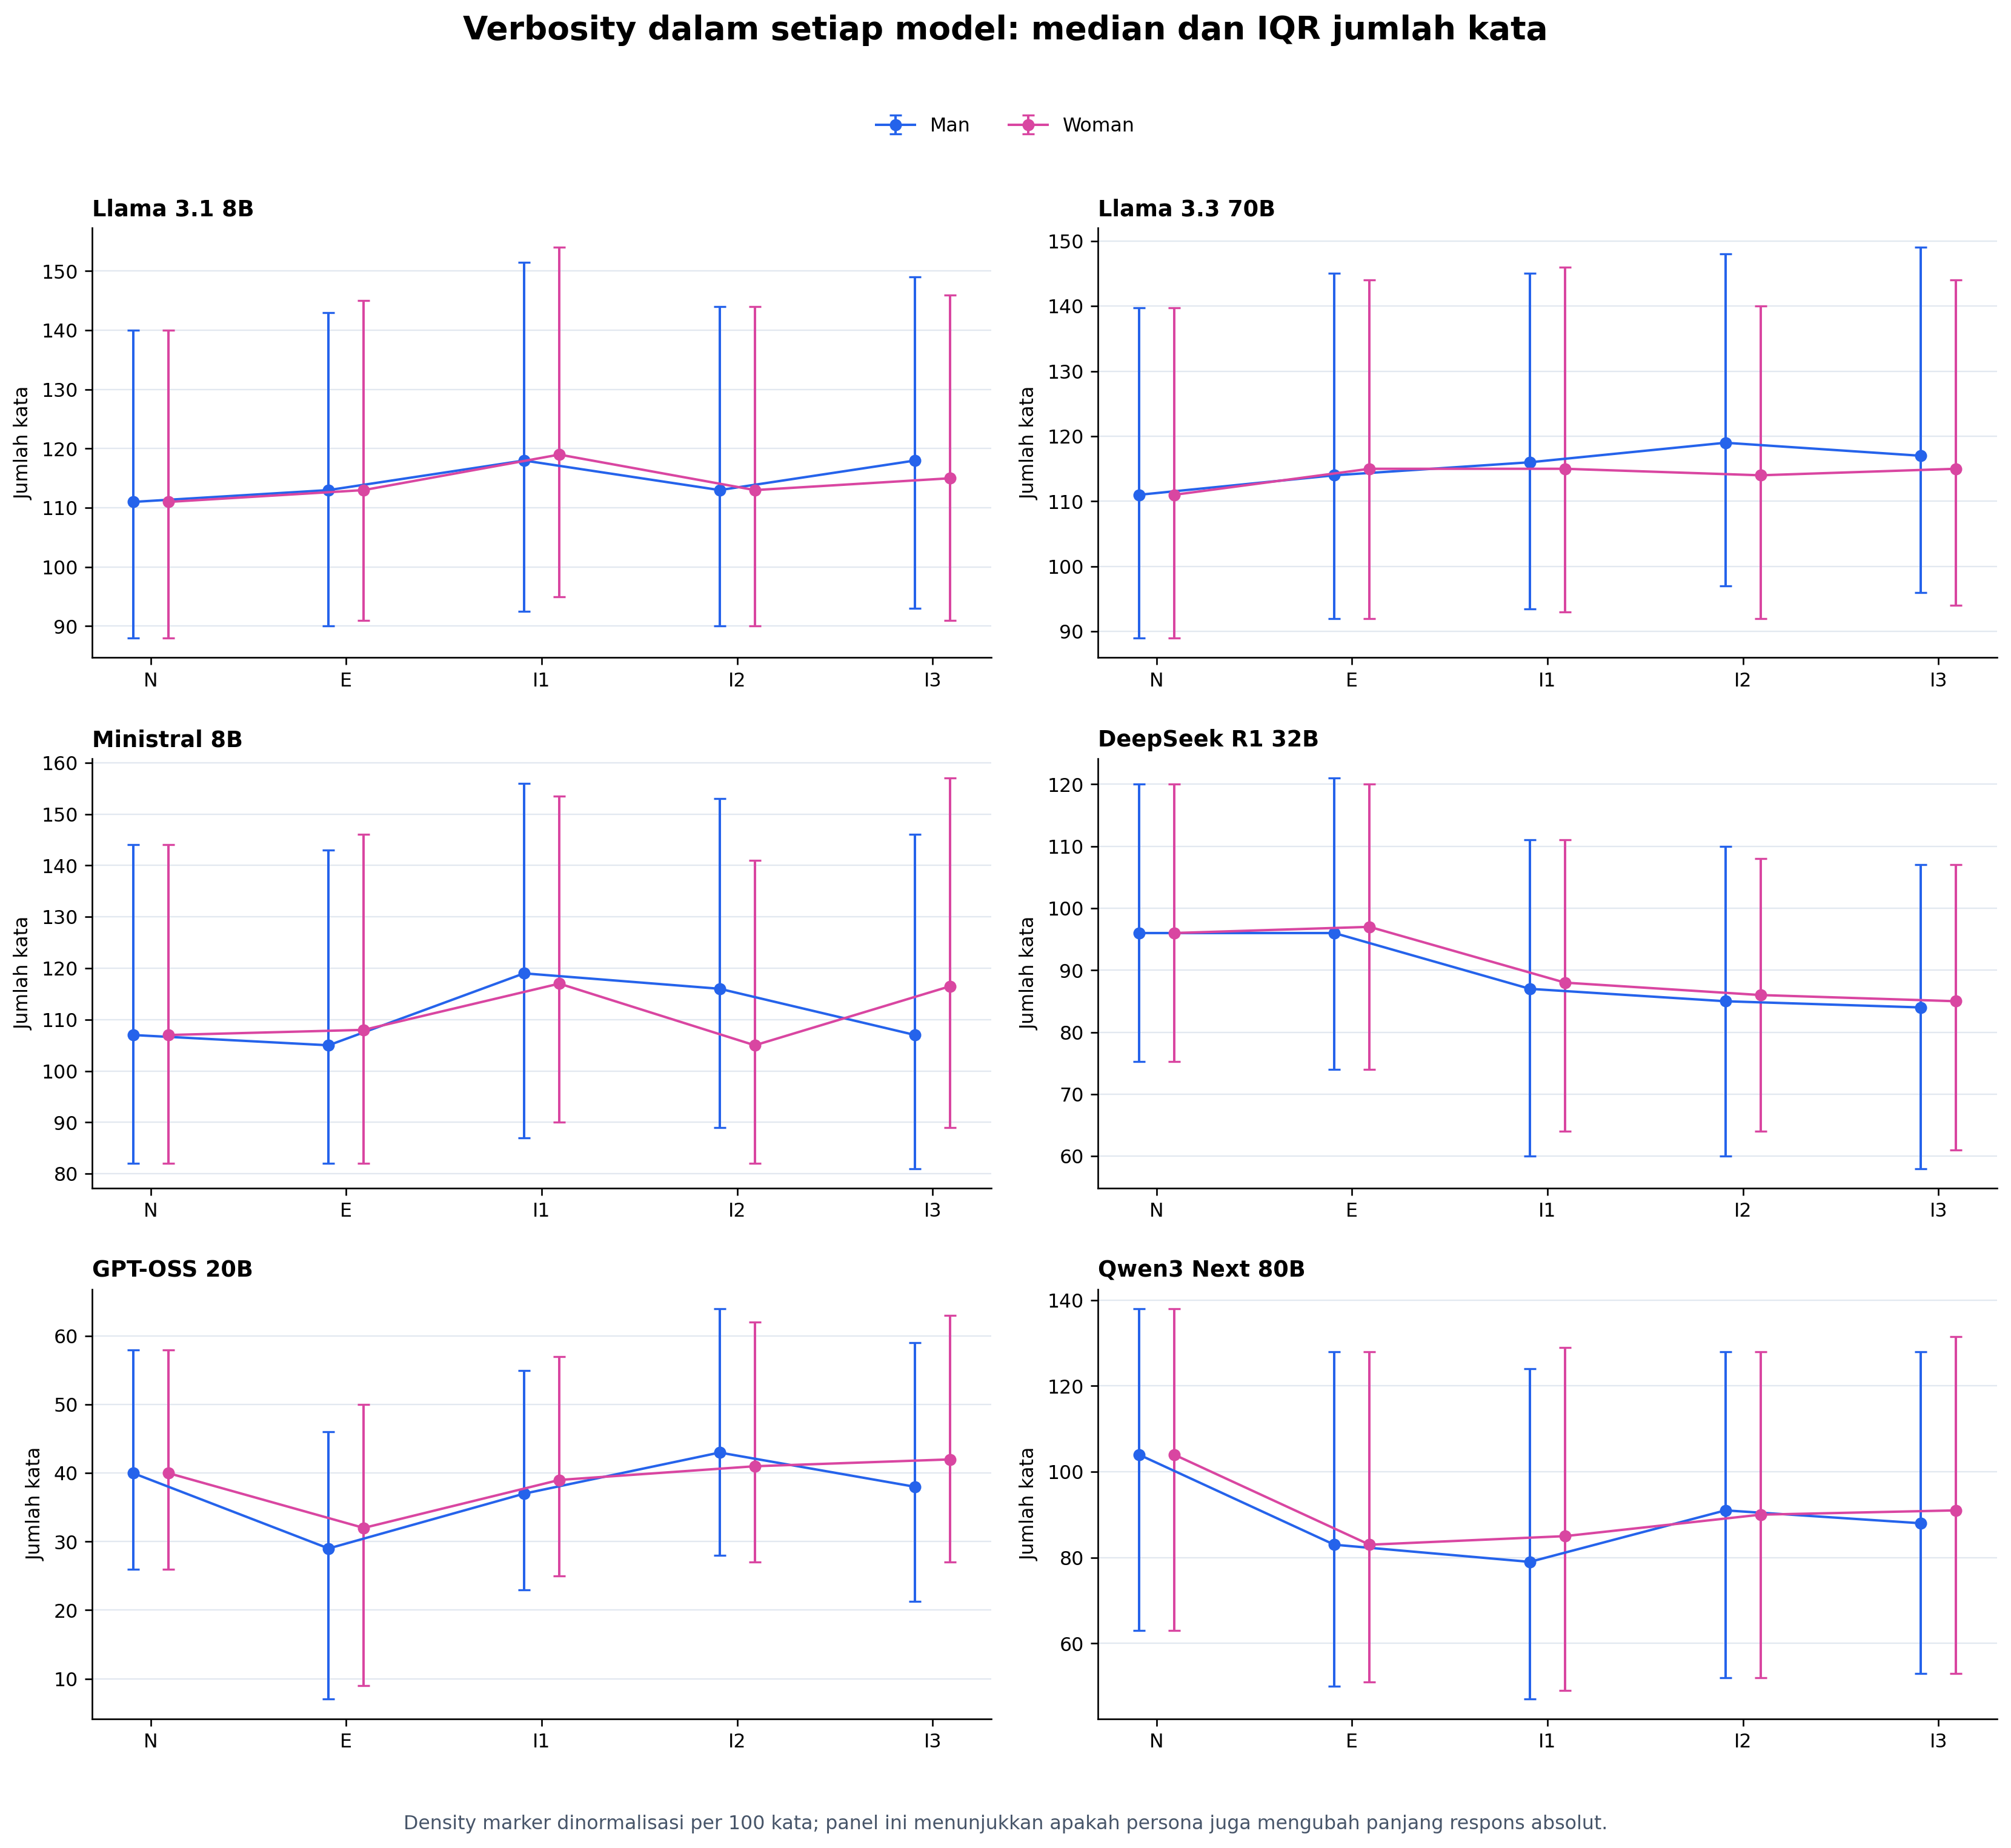

In [4]:
show_figure("02_verbosity_word_count_median_iqr.png", width=1450)


## 4. Effect map numerik: magnitude lebih dahulu

Sumbu-x adalah rank-biserial dari selisih berpasangan; sumbu-y adalah
`−log10(p_holm)`. Titik yang tinggi tetapi dekat nol menunjukkan hasil yang
signifikan namun kecil secara praktis. Ukuran titik mengikuti jumlah pasangan
yang benar-benar berubah (`n_nonzero`), sehingga efek ekstrem dari marker sangat
sparse tidak tampak setara dengan efek yang ditopang banyak pasangan.


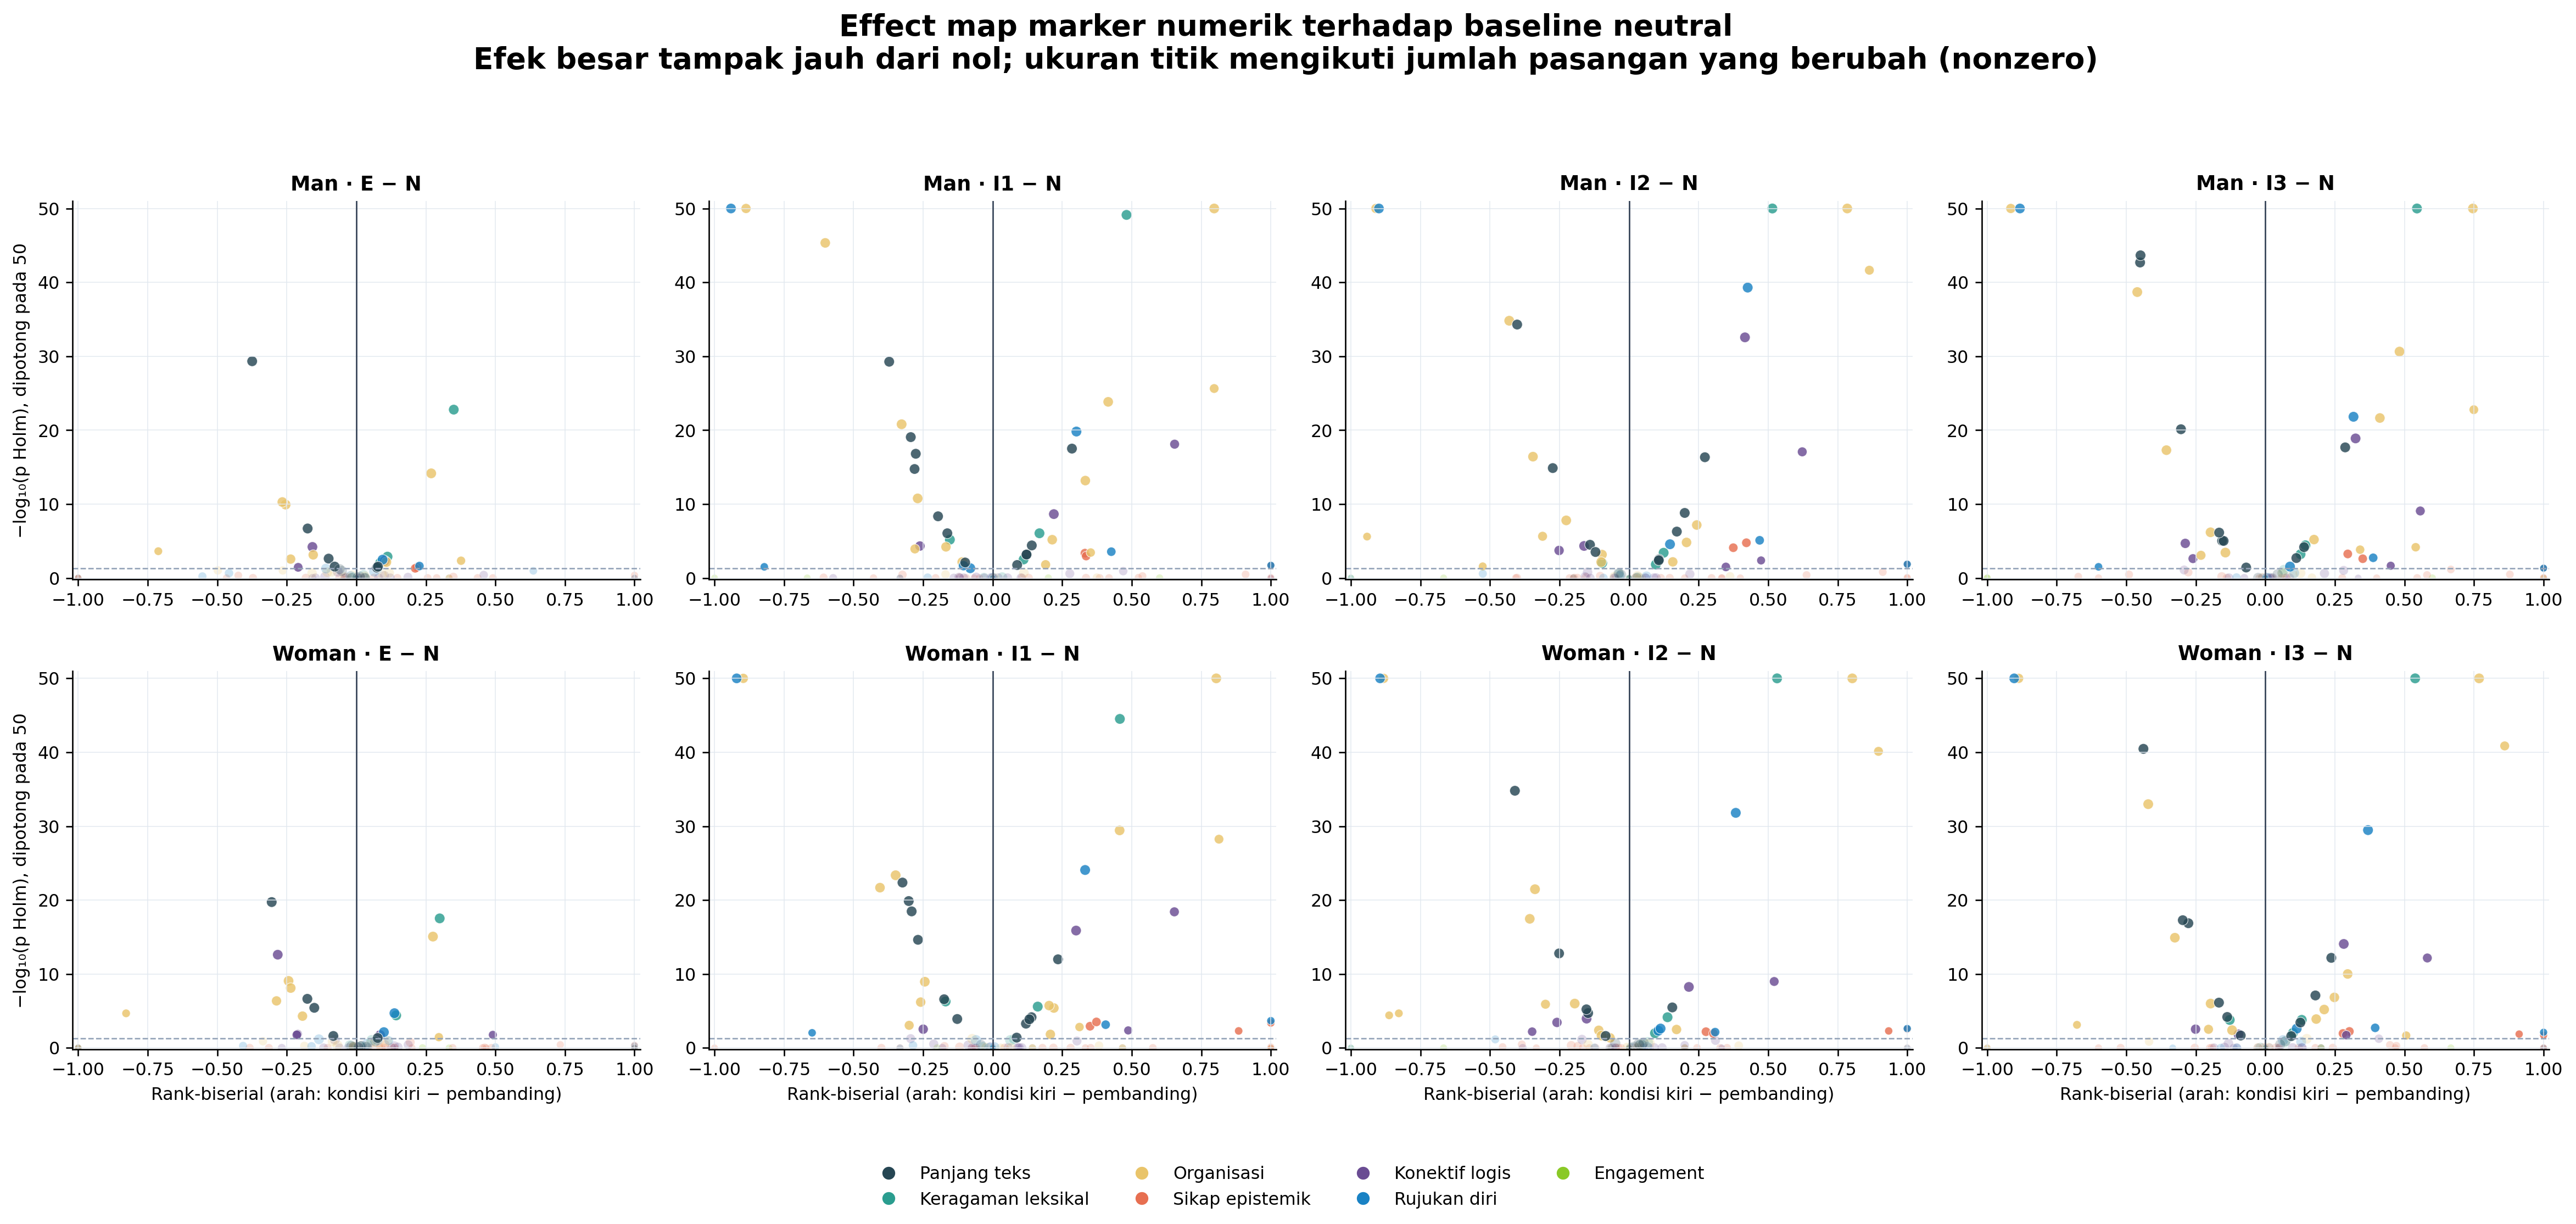

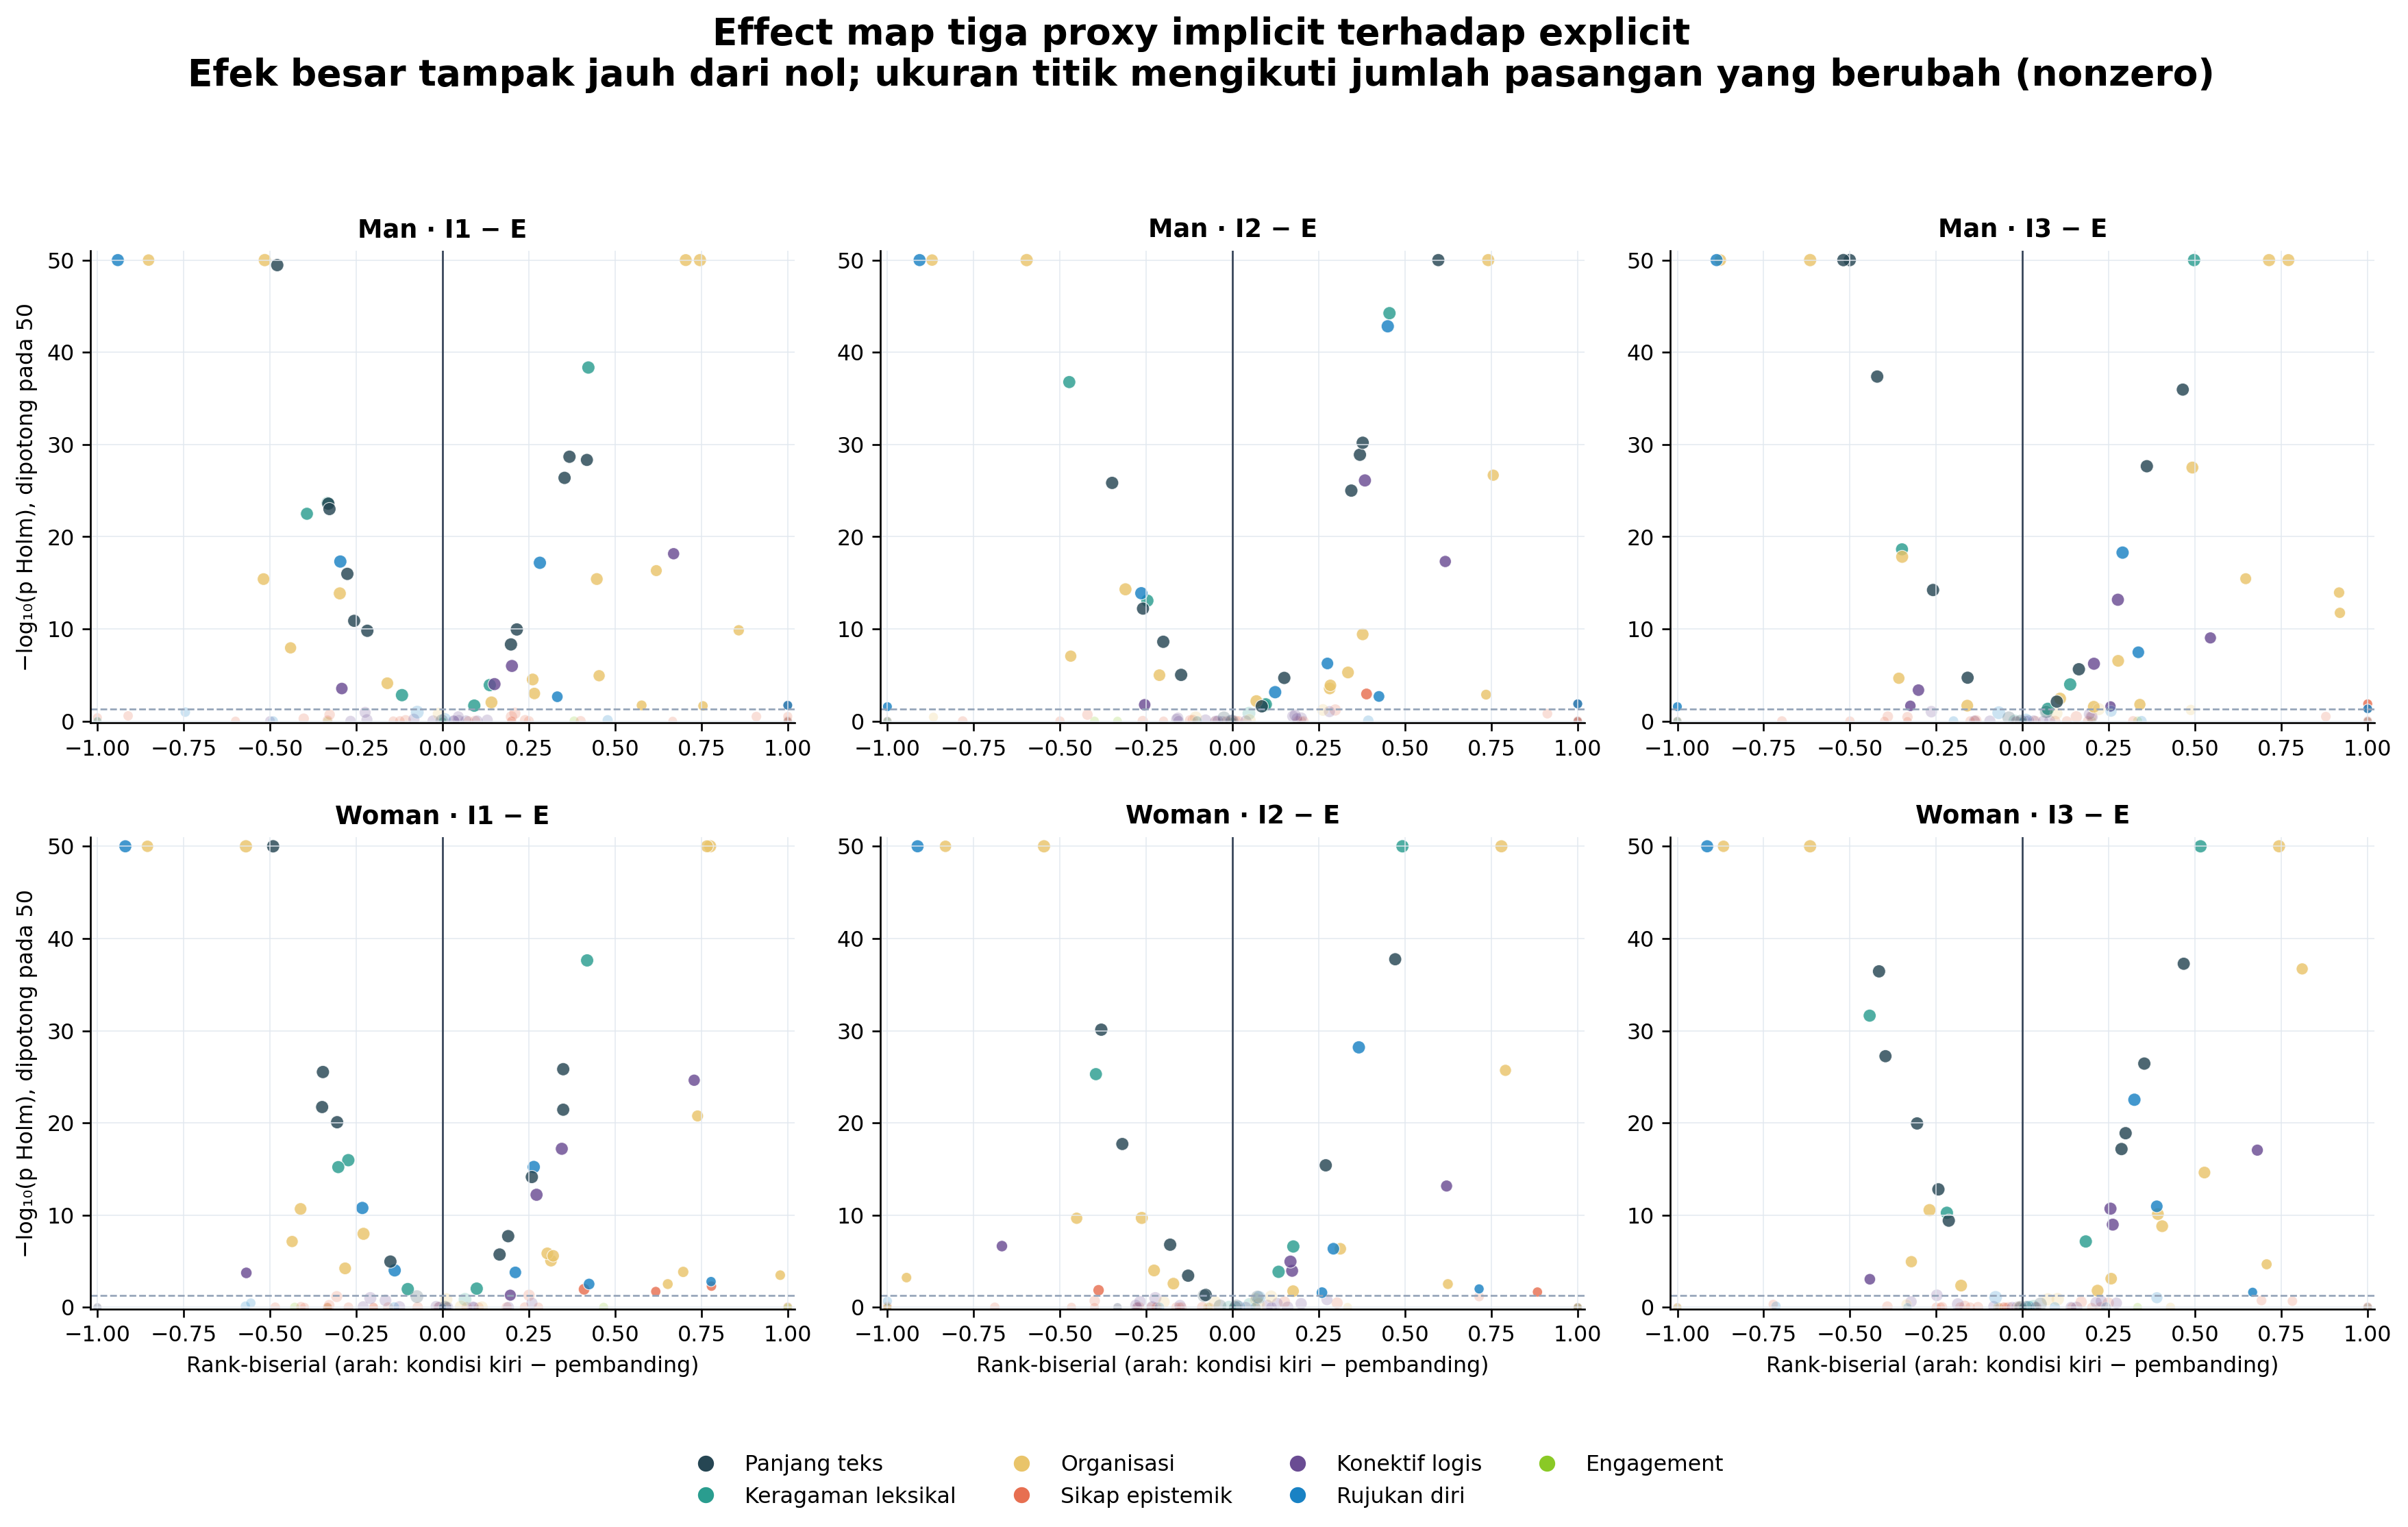

In [5]:
show_figure("03_numeric_effect_volcano_vs_neutral.png", width=1700)
show_figure("04_numeric_effect_volcano_implicit_vs_explicit.png", width=1600)


## 5. Forest plot ber-CI: I1, I2, dan I3 terpisah

Untuk marker yang sparse, *presence* sering lebih mudah dibaca daripada median
density yang dapat tetap nol. Titik menunjukkan perubahan proporsi respons yang
memuat marker; garis menunjukkan 95% paired bootstrap CI. Density numeriknya
tetap tersedia pada tabel utama dan volcano di atas.


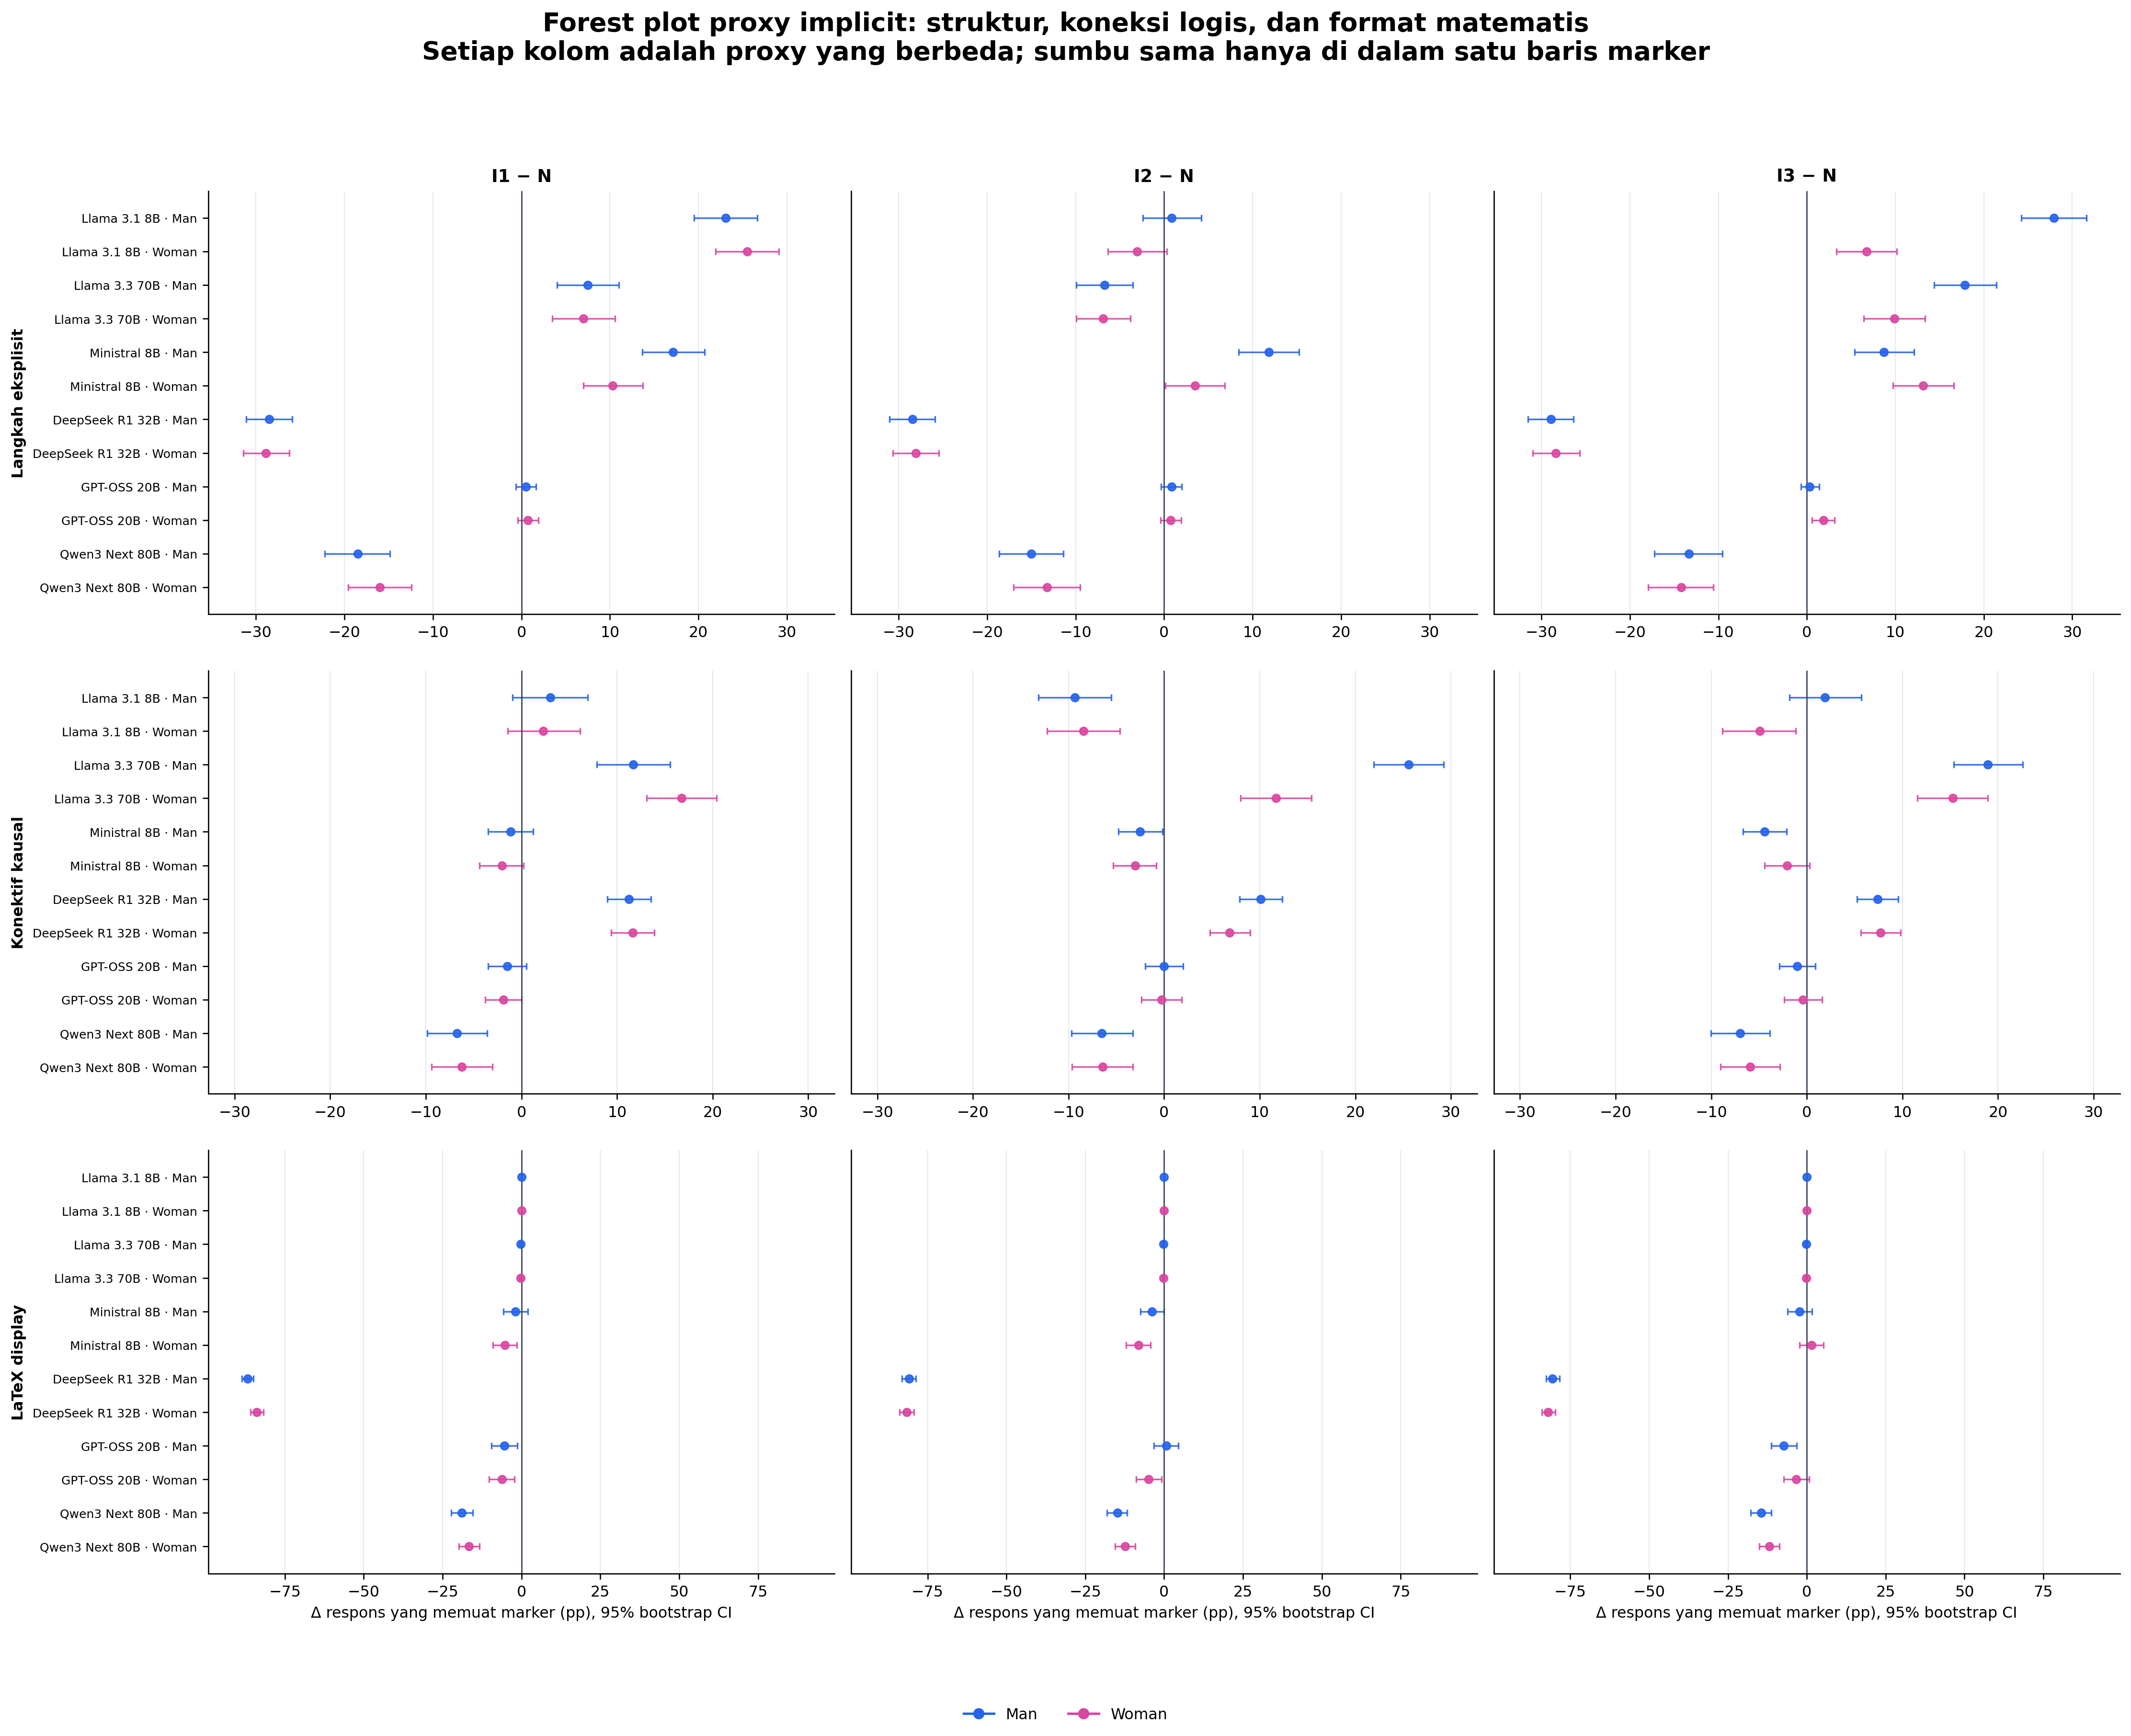

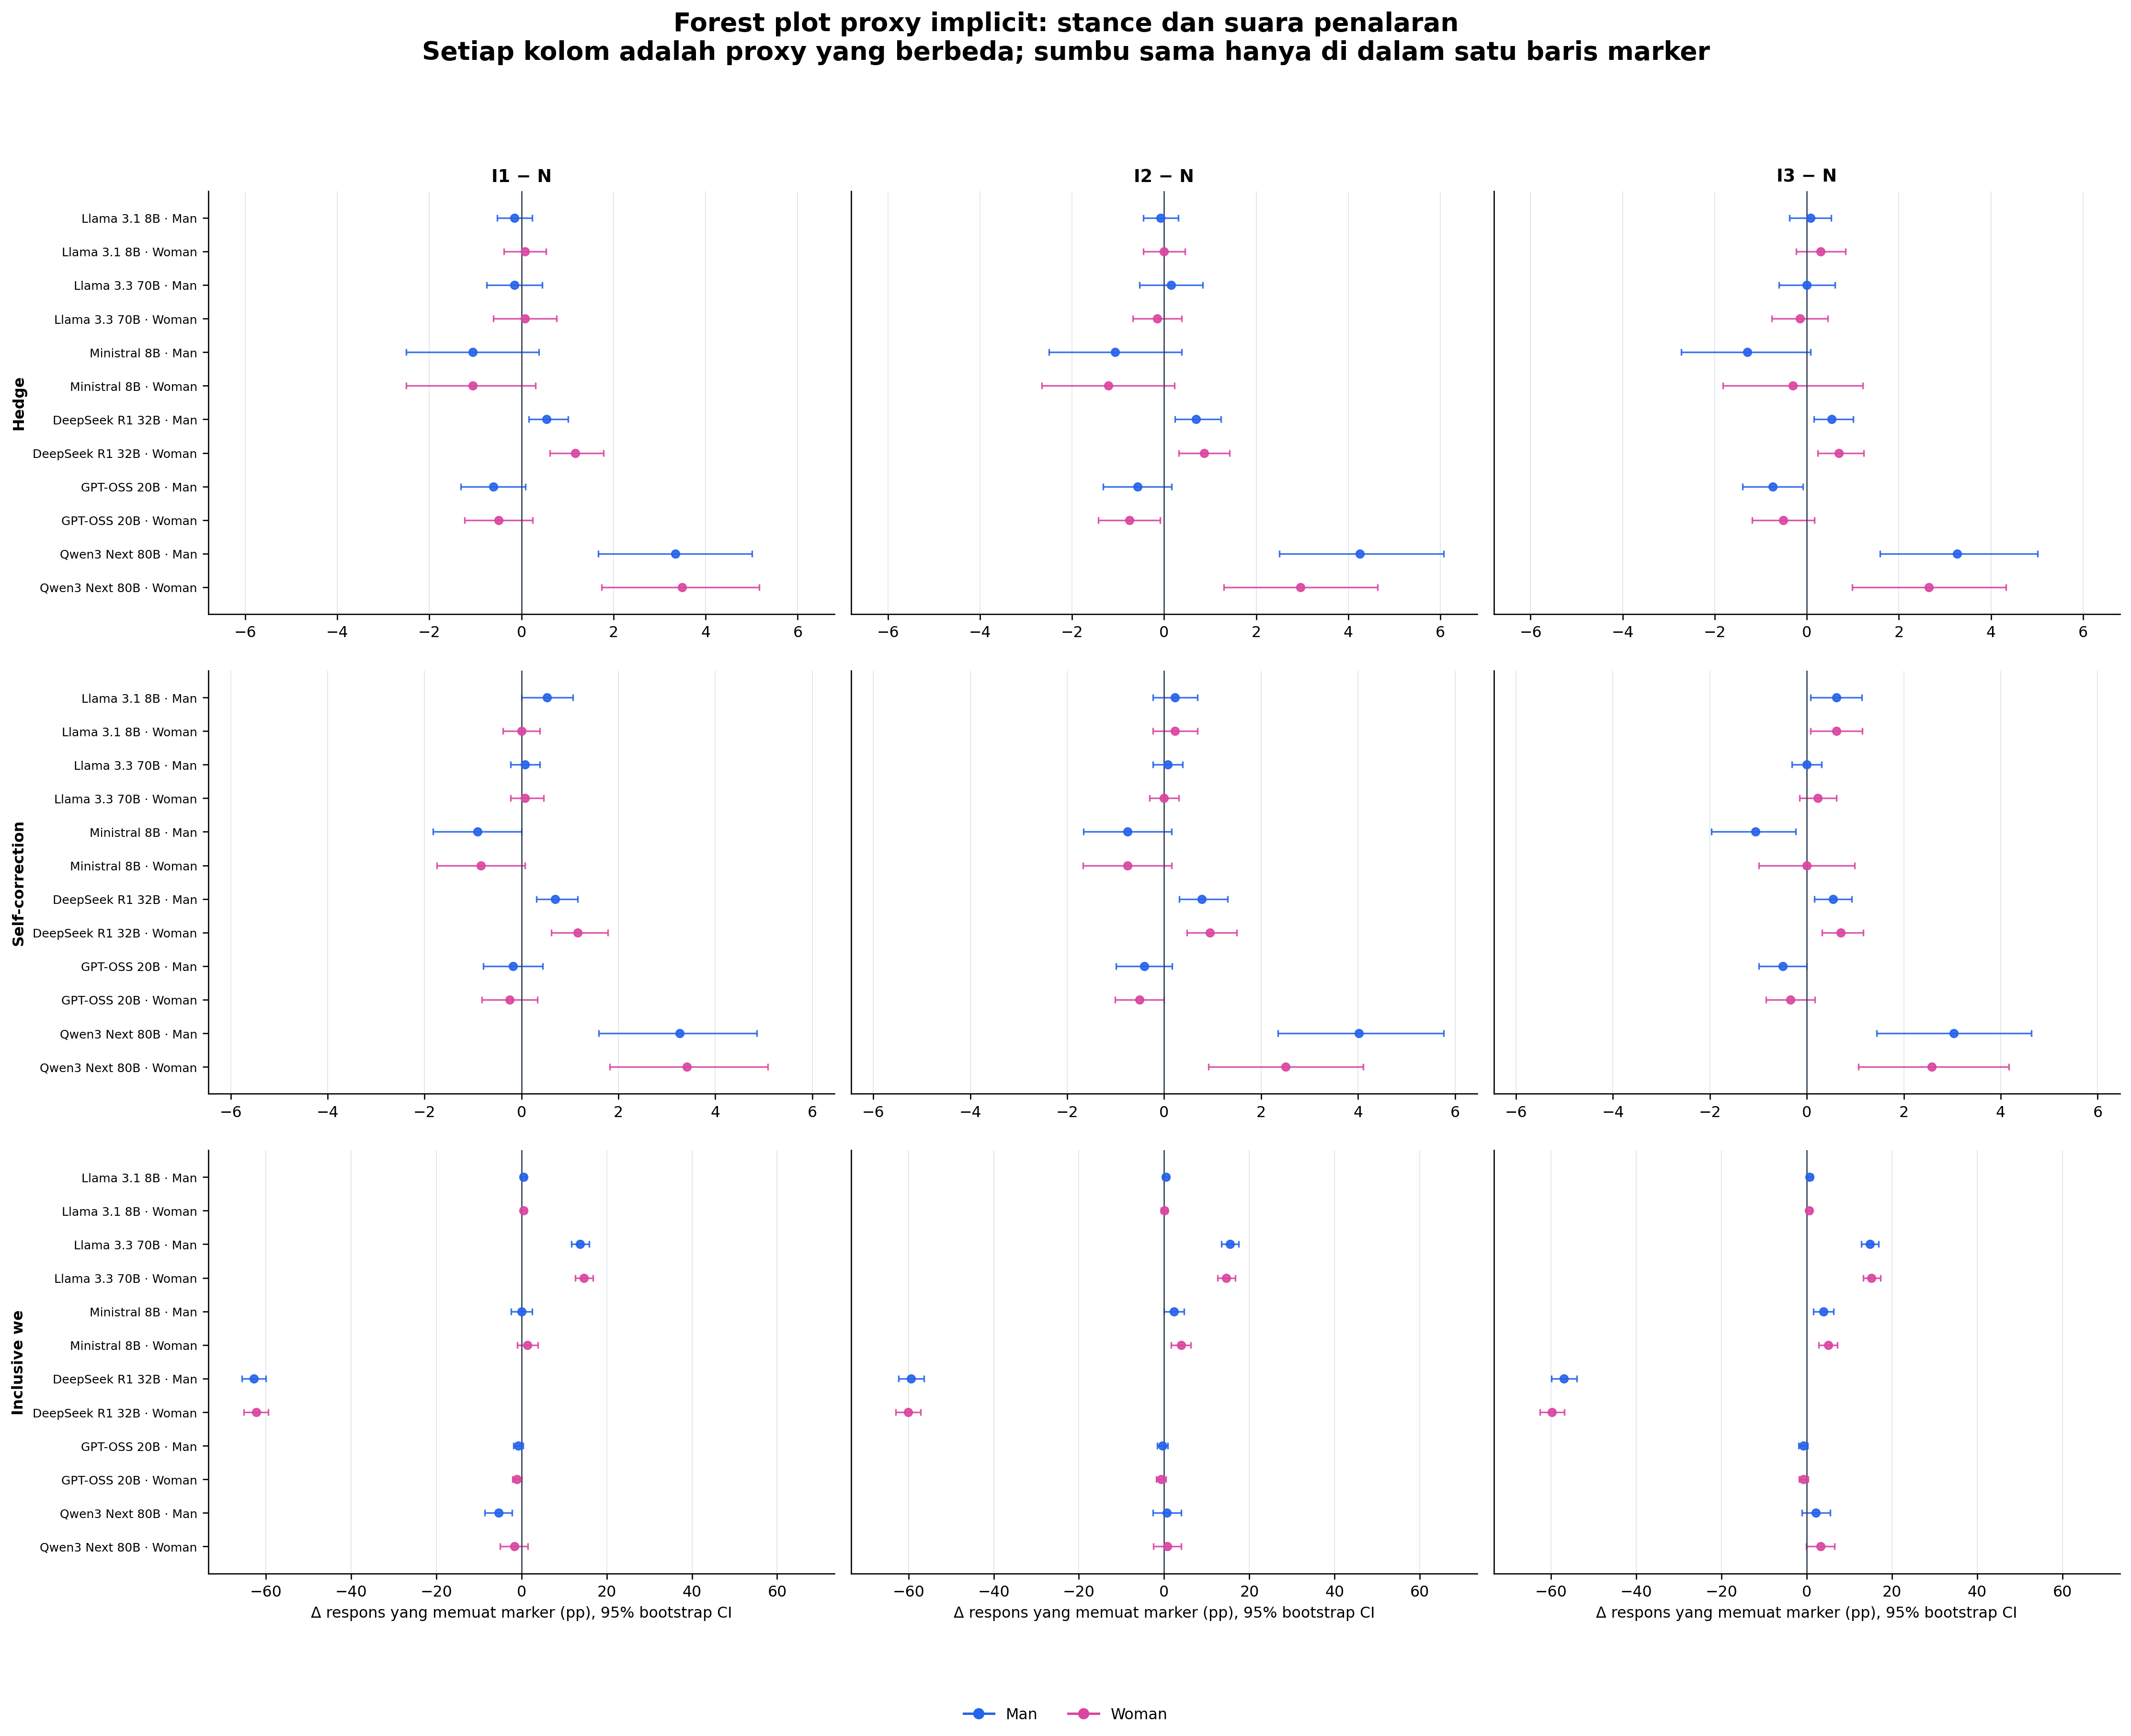

In [6]:
show_figure("05_proxy_presence_forest_structure_logic.png", width=1700)
show_figure("06_proxy_presence_forest_stance_voice.png", width=1700)


## 6. Sensitivitas correctness

Subset dibuat dengan urutan yang aman: pasangkan kondisi pada soal yang sama,
kemudian pertahankan pasangan jika **keduanya benar**. Analisis utama tidak
diganti oleh subset ini. Tujuannya hanya memeriksa apakah arah efek linguistik
berubah setelah confounding correctness dikurangi.


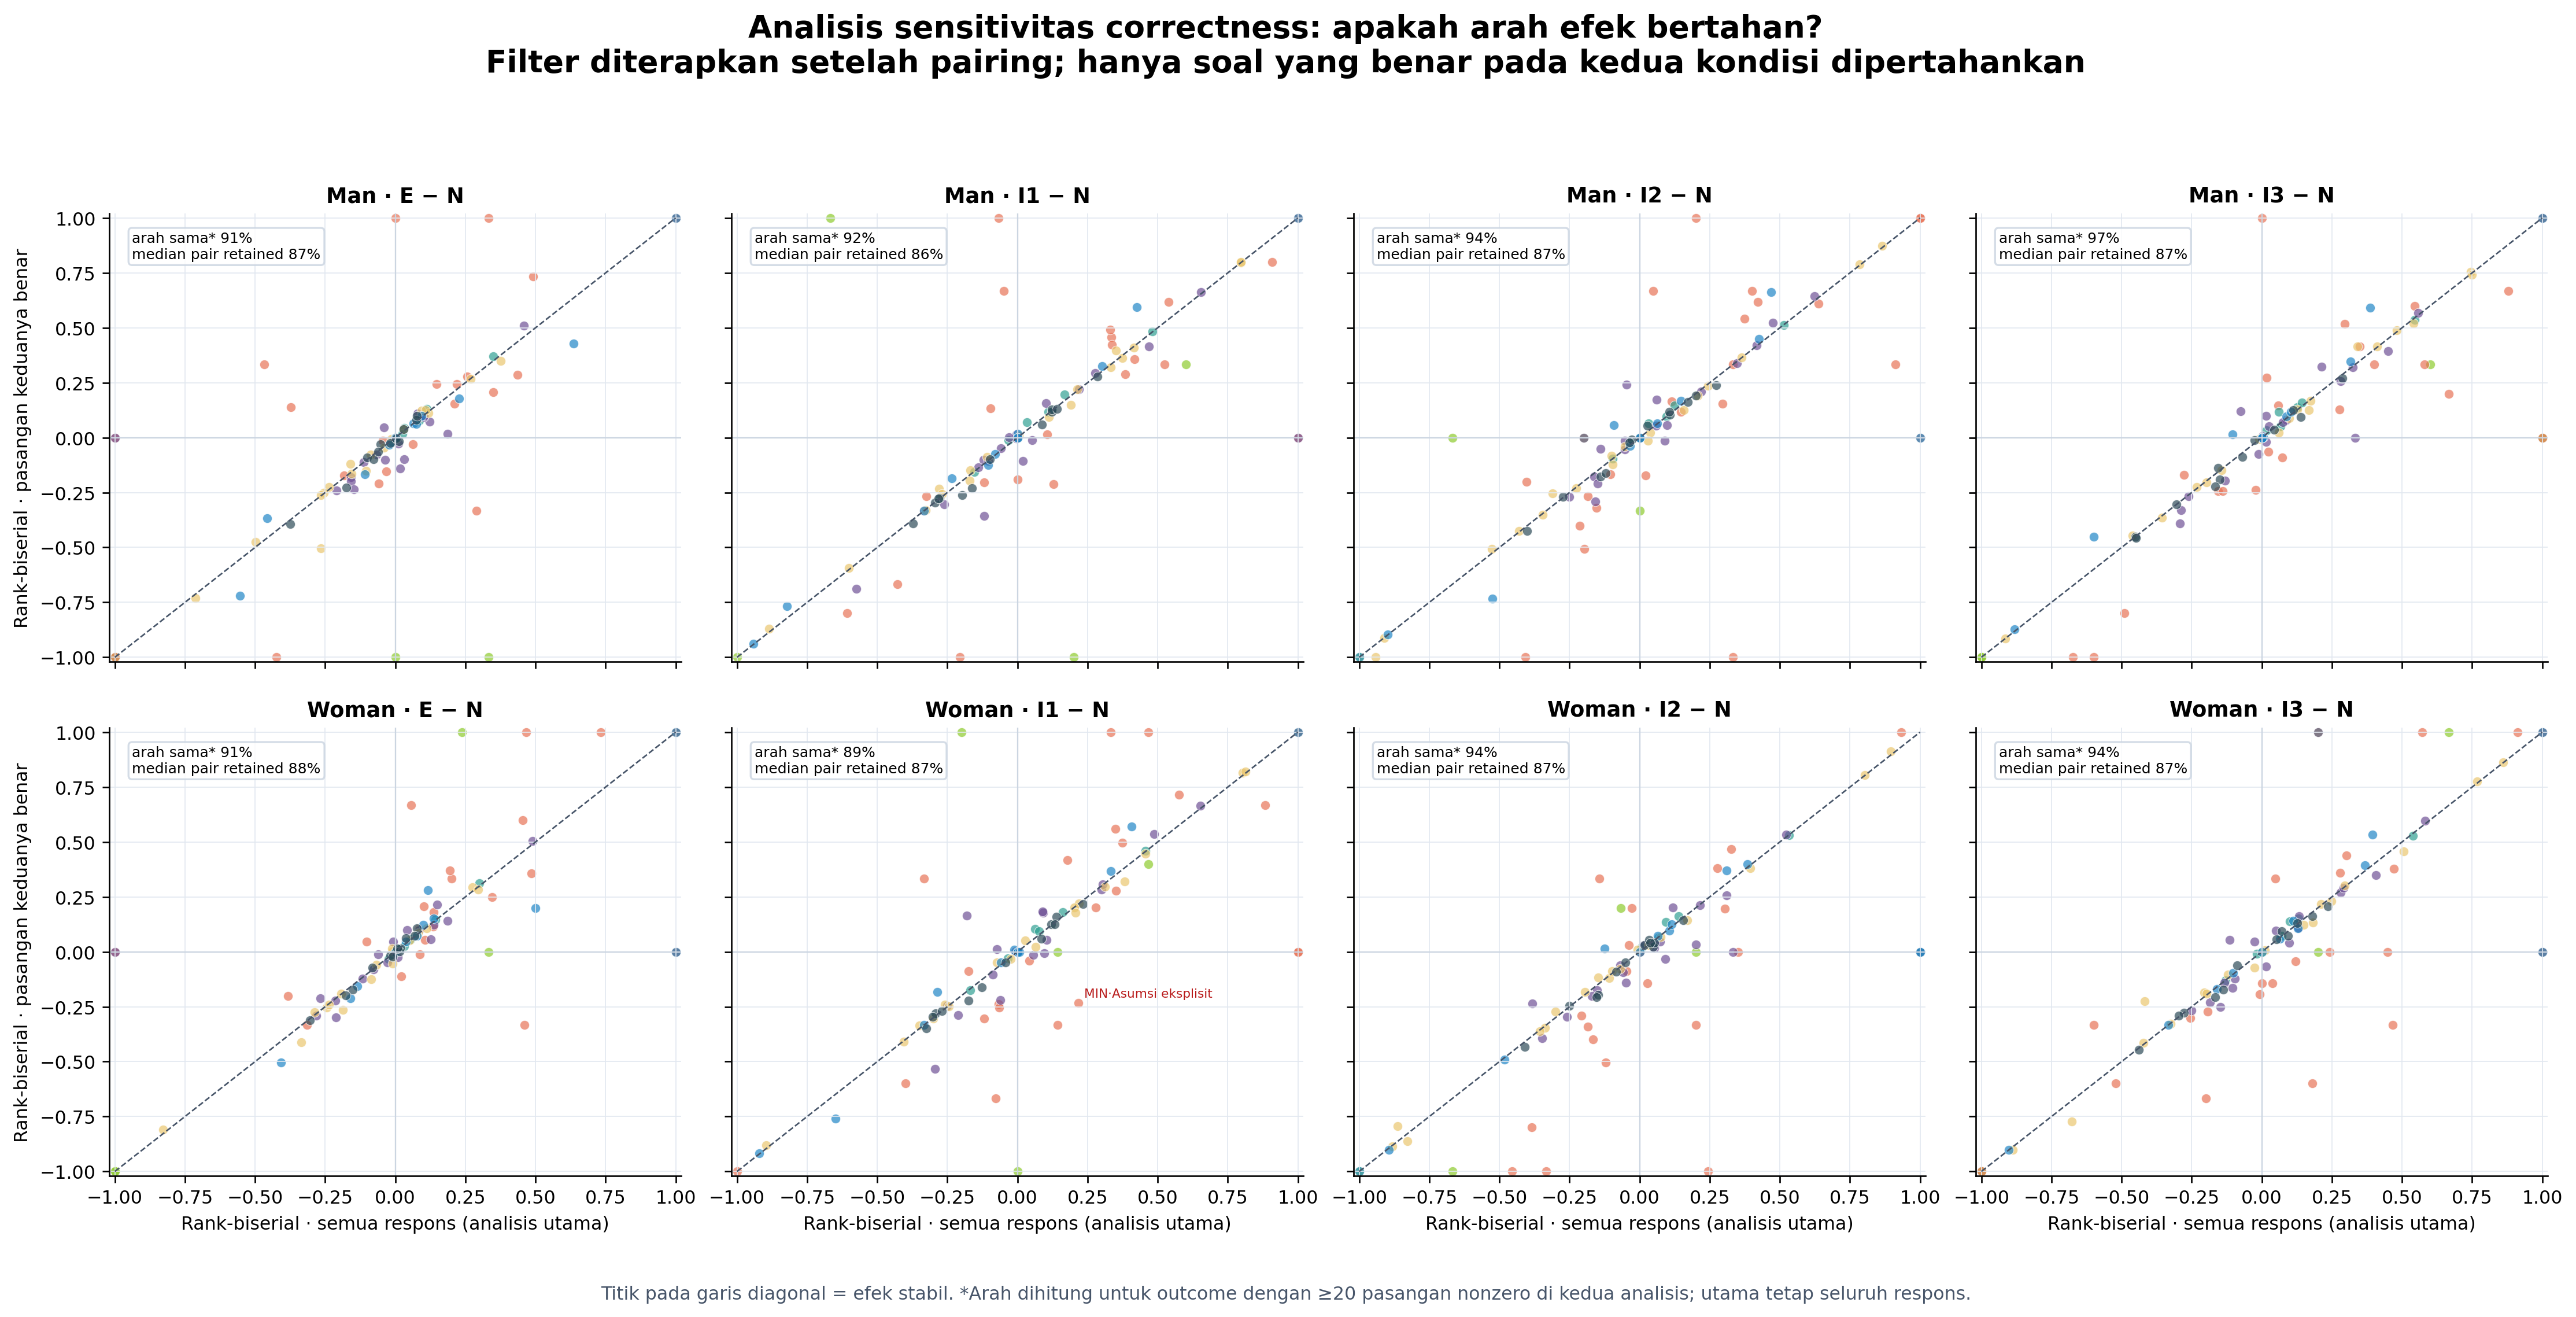

,identity,contrast_id,n_primary_tests,median_pairs_all_responses,median_pairs_both_correct,median_pair_retention,same_direction_rate_including_zero,n_tests_with_at_least_20_nonzero_pairs_in_both,same_direction_rate_supported,n_strict_sign_reversals,n_material_sign_reversals,spearman_rank_biserial,median_abs_rank_biserial_change
0,man,explicit_vs_neutral,96,1317.500000,1139.000000,87.2%,84.4%,65,90.8%,11,0,0.752,0.021
1,man,implicit_1_vs_explicit,96,1319.000000,1165.500000,89.7%,86.5%,60,90.0%,10,0,0.887,0.031
2,man,implicit_1_vs_neutral,96,1317.500000,1137.500000,86.4%,86.5%,66,92.4%,11,0,0.814,0.021
3,man,implicit_2_vs_explicit,96,1318.500000,1173.000000,89.9%,83.3%,60,96.7%,8,0,0.818,0.024
4,man,implicit_2_vs_neutral,96,1317.000000,1138.500000,87.0%,87.5%,65,93.8%,6,0,0.860,0.023
5,man,implicit_3_vs_explicit,96,1318.000000,1176.000000,89.9%,87.5%,61,96.7%,5,0,0.887,0.027
6,man,implicit_3_vs_neutral,96,1316.500000,1132.000000,87.1%,90.6%,64,96.9%,5,0,0.892,0.018
7,woman,explicit_vs_neutral,96,1316.500000,1149.000000,87.7%,85.4%,66,90.9%,8,0,0.829,0.021
8,woman,implicit_1_vs_explicit,96,1316.000000,1163.000000,89.9%,87.5%,61,96.7%,8,0,0.846,0.033
9,woman,implicit_1_vs_neutral,96,1315.500000,1139.000000,87.0%,83.3%,65,89.2%,12,1,0.825,0.024


In [7]:
show_figure("07_correctness_sensitivity_effect_concordance.png", width=1650)
sensitivity = pd.read_csv(BUNDLE_DIR / "correctness_sensitivity_summary.csv")
display(
    sensitivity.style.format({
        "median_pair_retention": "{:.1%}",
        "same_direction_rate_including_zero": "{:.1%}",
        "same_direction_rate_supported": "{:.1%}",
        "spearman_rank_biserial": "{:.3f}",
        "median_abs_rank_biserial_change": "{:.3f}",
    })
)


## 7. Opening sebagai komposisi multinomial

Setiap respons memiliki satu kategori pembukaan, sehingga seluruh segmen dalam
satu bar berjumlah 100%. Inferensi pasangan dilakukan sekali per kontras dengan
Stuart–Maxwell marginal homogeneity; sebelas kategori tidak diperlakukan sebagai
sebelas cerita independen.


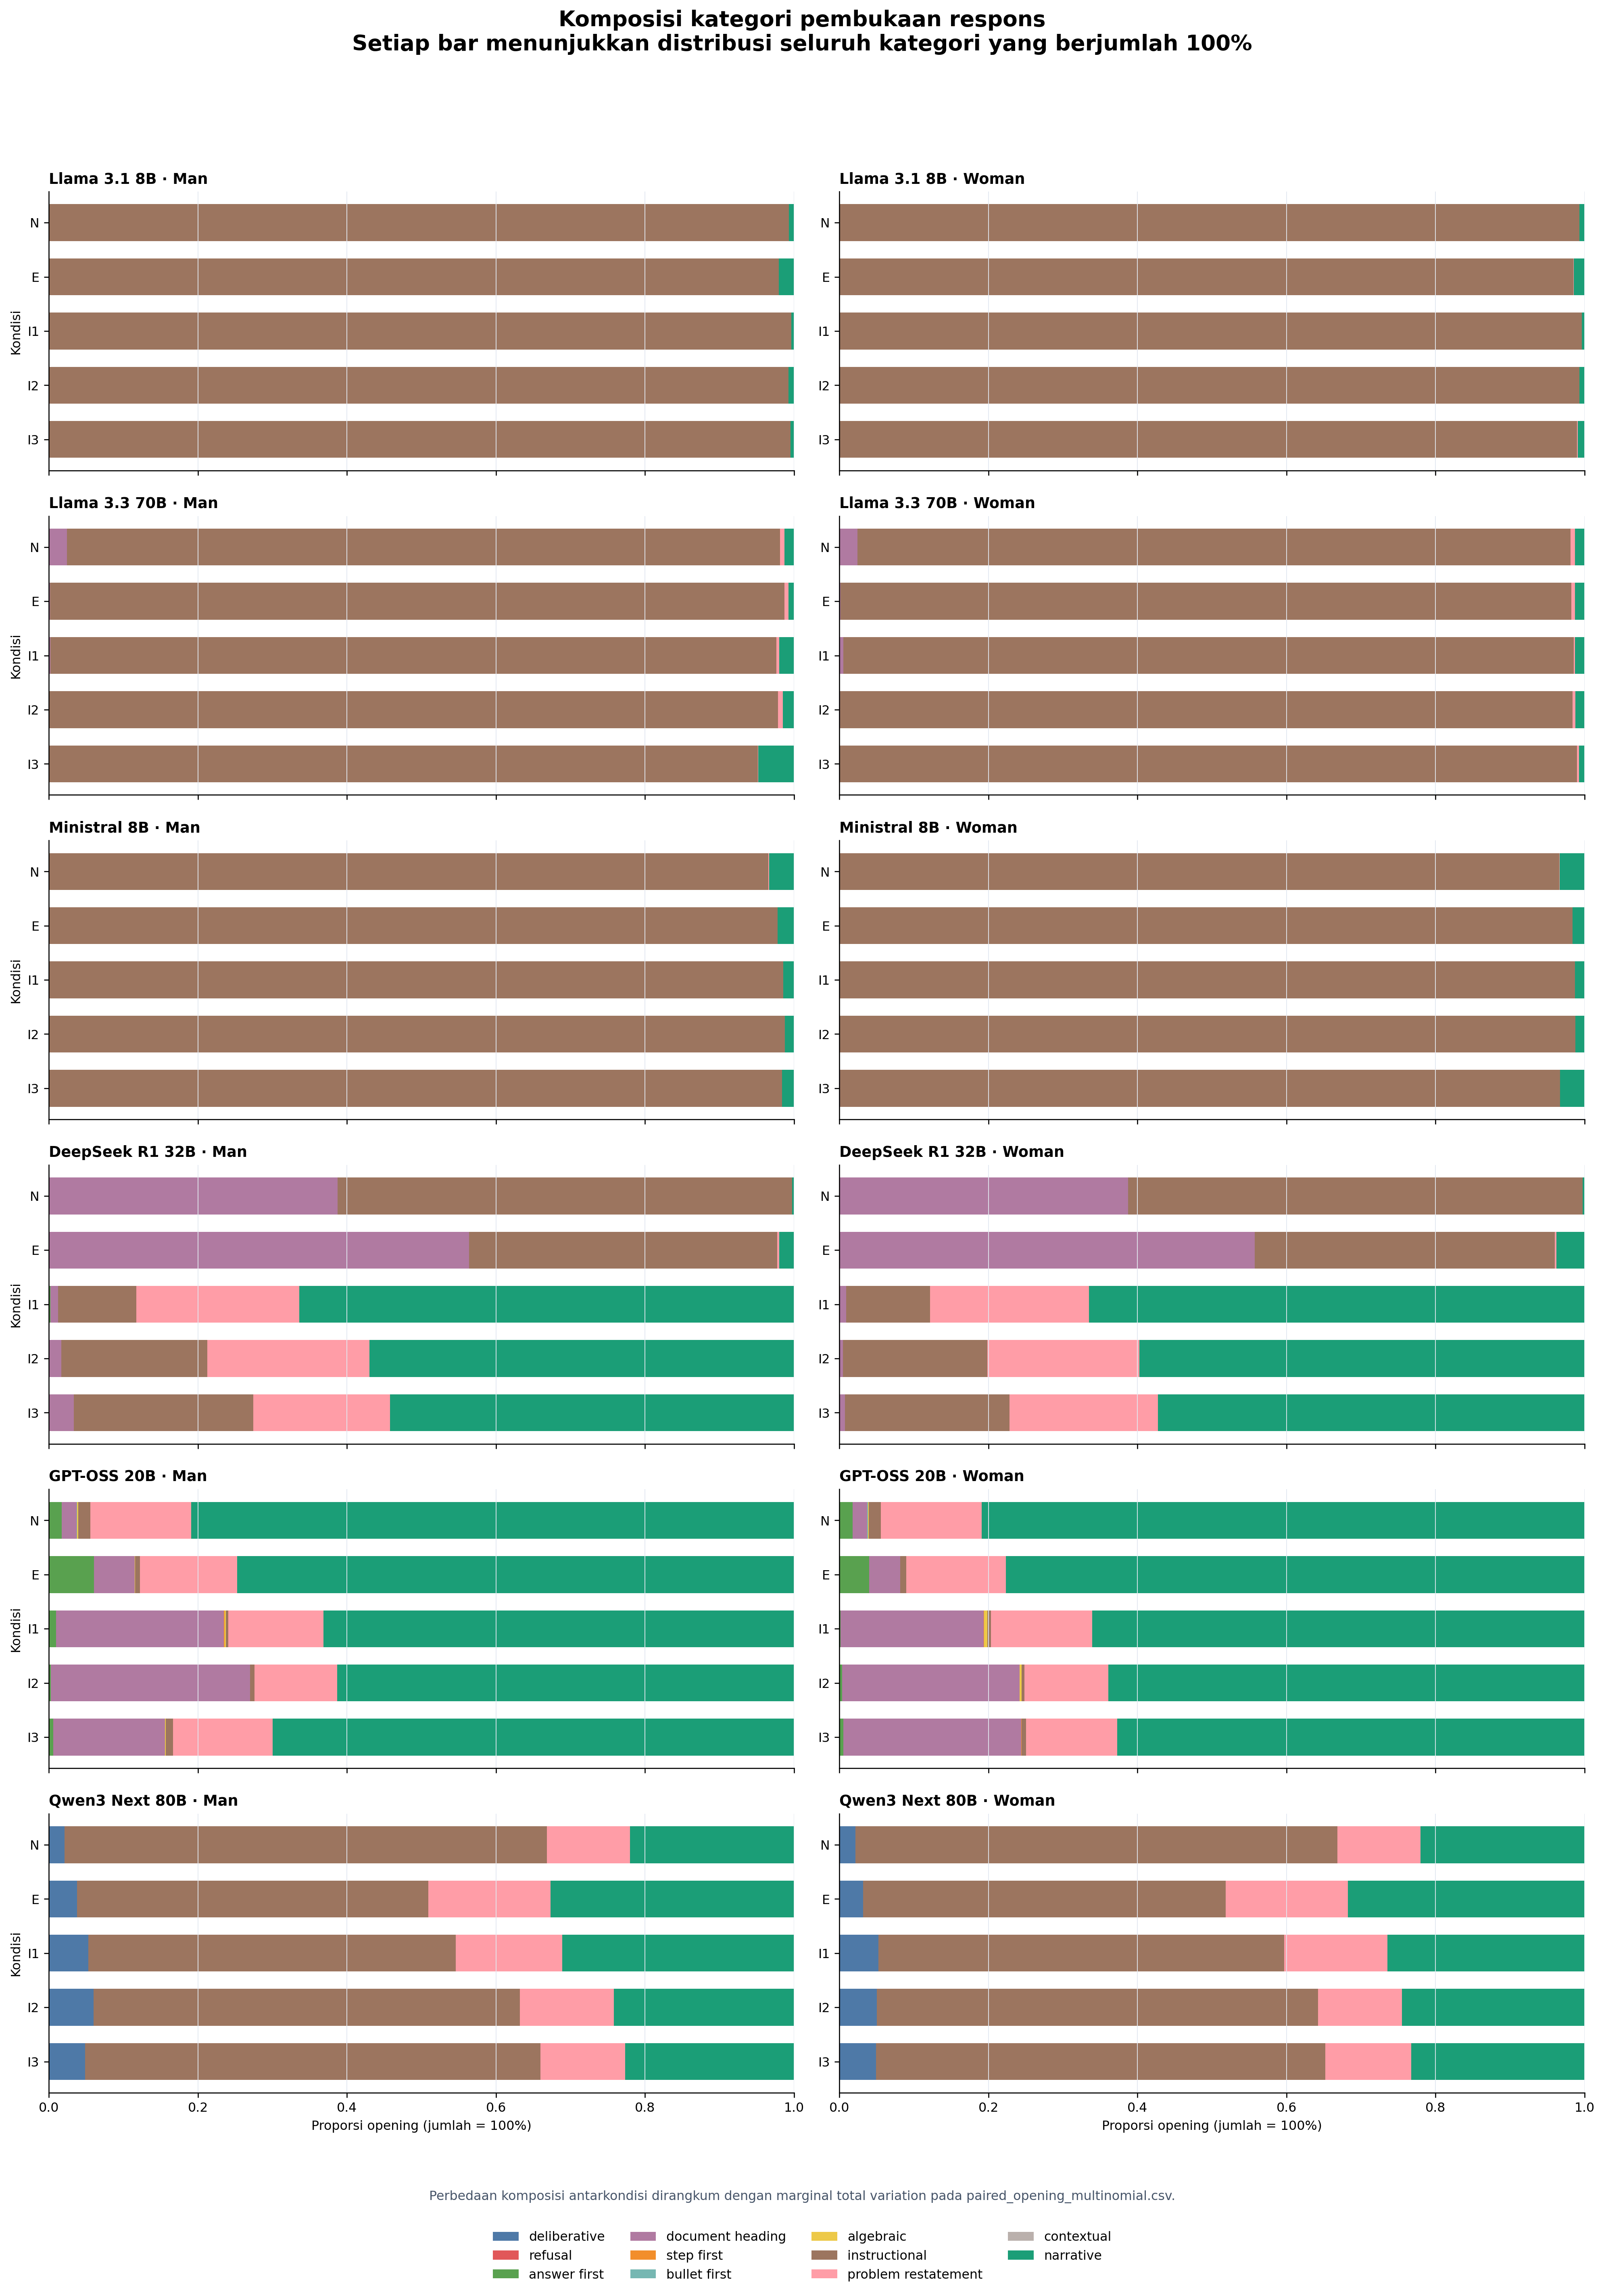

,model_id,identity,contrast_id,n_pairs,same_category_rate,marginal_total_variation,p_holm
1,deepseek_deepseek-r1-distill-qwen-32b,man,implicit_1_vs_neutral,1290,7.5%,88.3%,6.33e-245
8,deepseek_deepseek-r1-distill-qwen-32b,woman,implicit_1_vs_neutral,1288,8.2%,87.7%,2.33e-244
4,deepseek_deepseek-r1-distill-qwen-32b,man,implicit_1_vs_explicit,1289,6.9%,86.3%,1.11e-239
11,deepseek_deepseek-r1-distill-qwen-32b,woman,implicit_1_vs_explicit,1288,8.9%,83.9%,2.04e-234
9,deepseek_deepseek-r1-distill-qwen-32b,woman,implicit_2_vs_neutral,1268,13.3%,80.1%,7.56e-223
2,deepseek_deepseek-r1-distill-qwen-32b,man,implicit_2_vs_neutral,1294,13.9%,78.7%,9.08e-223
10,deepseek_deepseek-r1-distill-qwen-32b,woman,implicit_3_vs_neutral,1294,13.7%,77.2%,3.91e-221
5,deepseek_deepseek-r1-distill-qwen-32b,man,implicit_2_vs_explicit,1293,11.4%,76.4%,8.92e-219
12,deepseek_deepseek-r1-distill-qwen-32b,woman,implicit_2_vs_explicit,1271,12.1%,76.1%,1.55e-216
13,deepseek_deepseek-r1-distill-qwen-32b,woman,implicit_3_vs_explicit,1294,12.3%,73.1%,3.31e-213


In [8]:
show_figure("08_opening_composition_100pct.png", width=1500)
opening_joint = pd.read_csv(BUNDLE_DIR / "paired_opening_multinomial.csv")
display(
    opening_joint.sort_values("marginal_total_variation", ascending=False)
    [["model_id", "identity", "contrast_id", "n_pairs", "same_category_rate",
      "marginal_total_variation", "p_holm"]]
    .head(20)
    .style.format({
        "same_category_rate": "{:.1%}",
        "marginal_total_variation": "{:.1%}",
        "p_holm": "{:.3g}",
    })
)


## 8. Token distingtif umum: ranked lollipop

Bobot adalah selisih prevalensi token biner per respons, dipasangkan pada soal
yang sama dan dirata-ratakan dengan bobot setara per model. Nilai eksak tetap
terlihat; token hanya masuk jika arahnya konsisten pada sedikitnya empat dari
enam model. Sumbu menunjukkan selisih prevalensi token per respons.


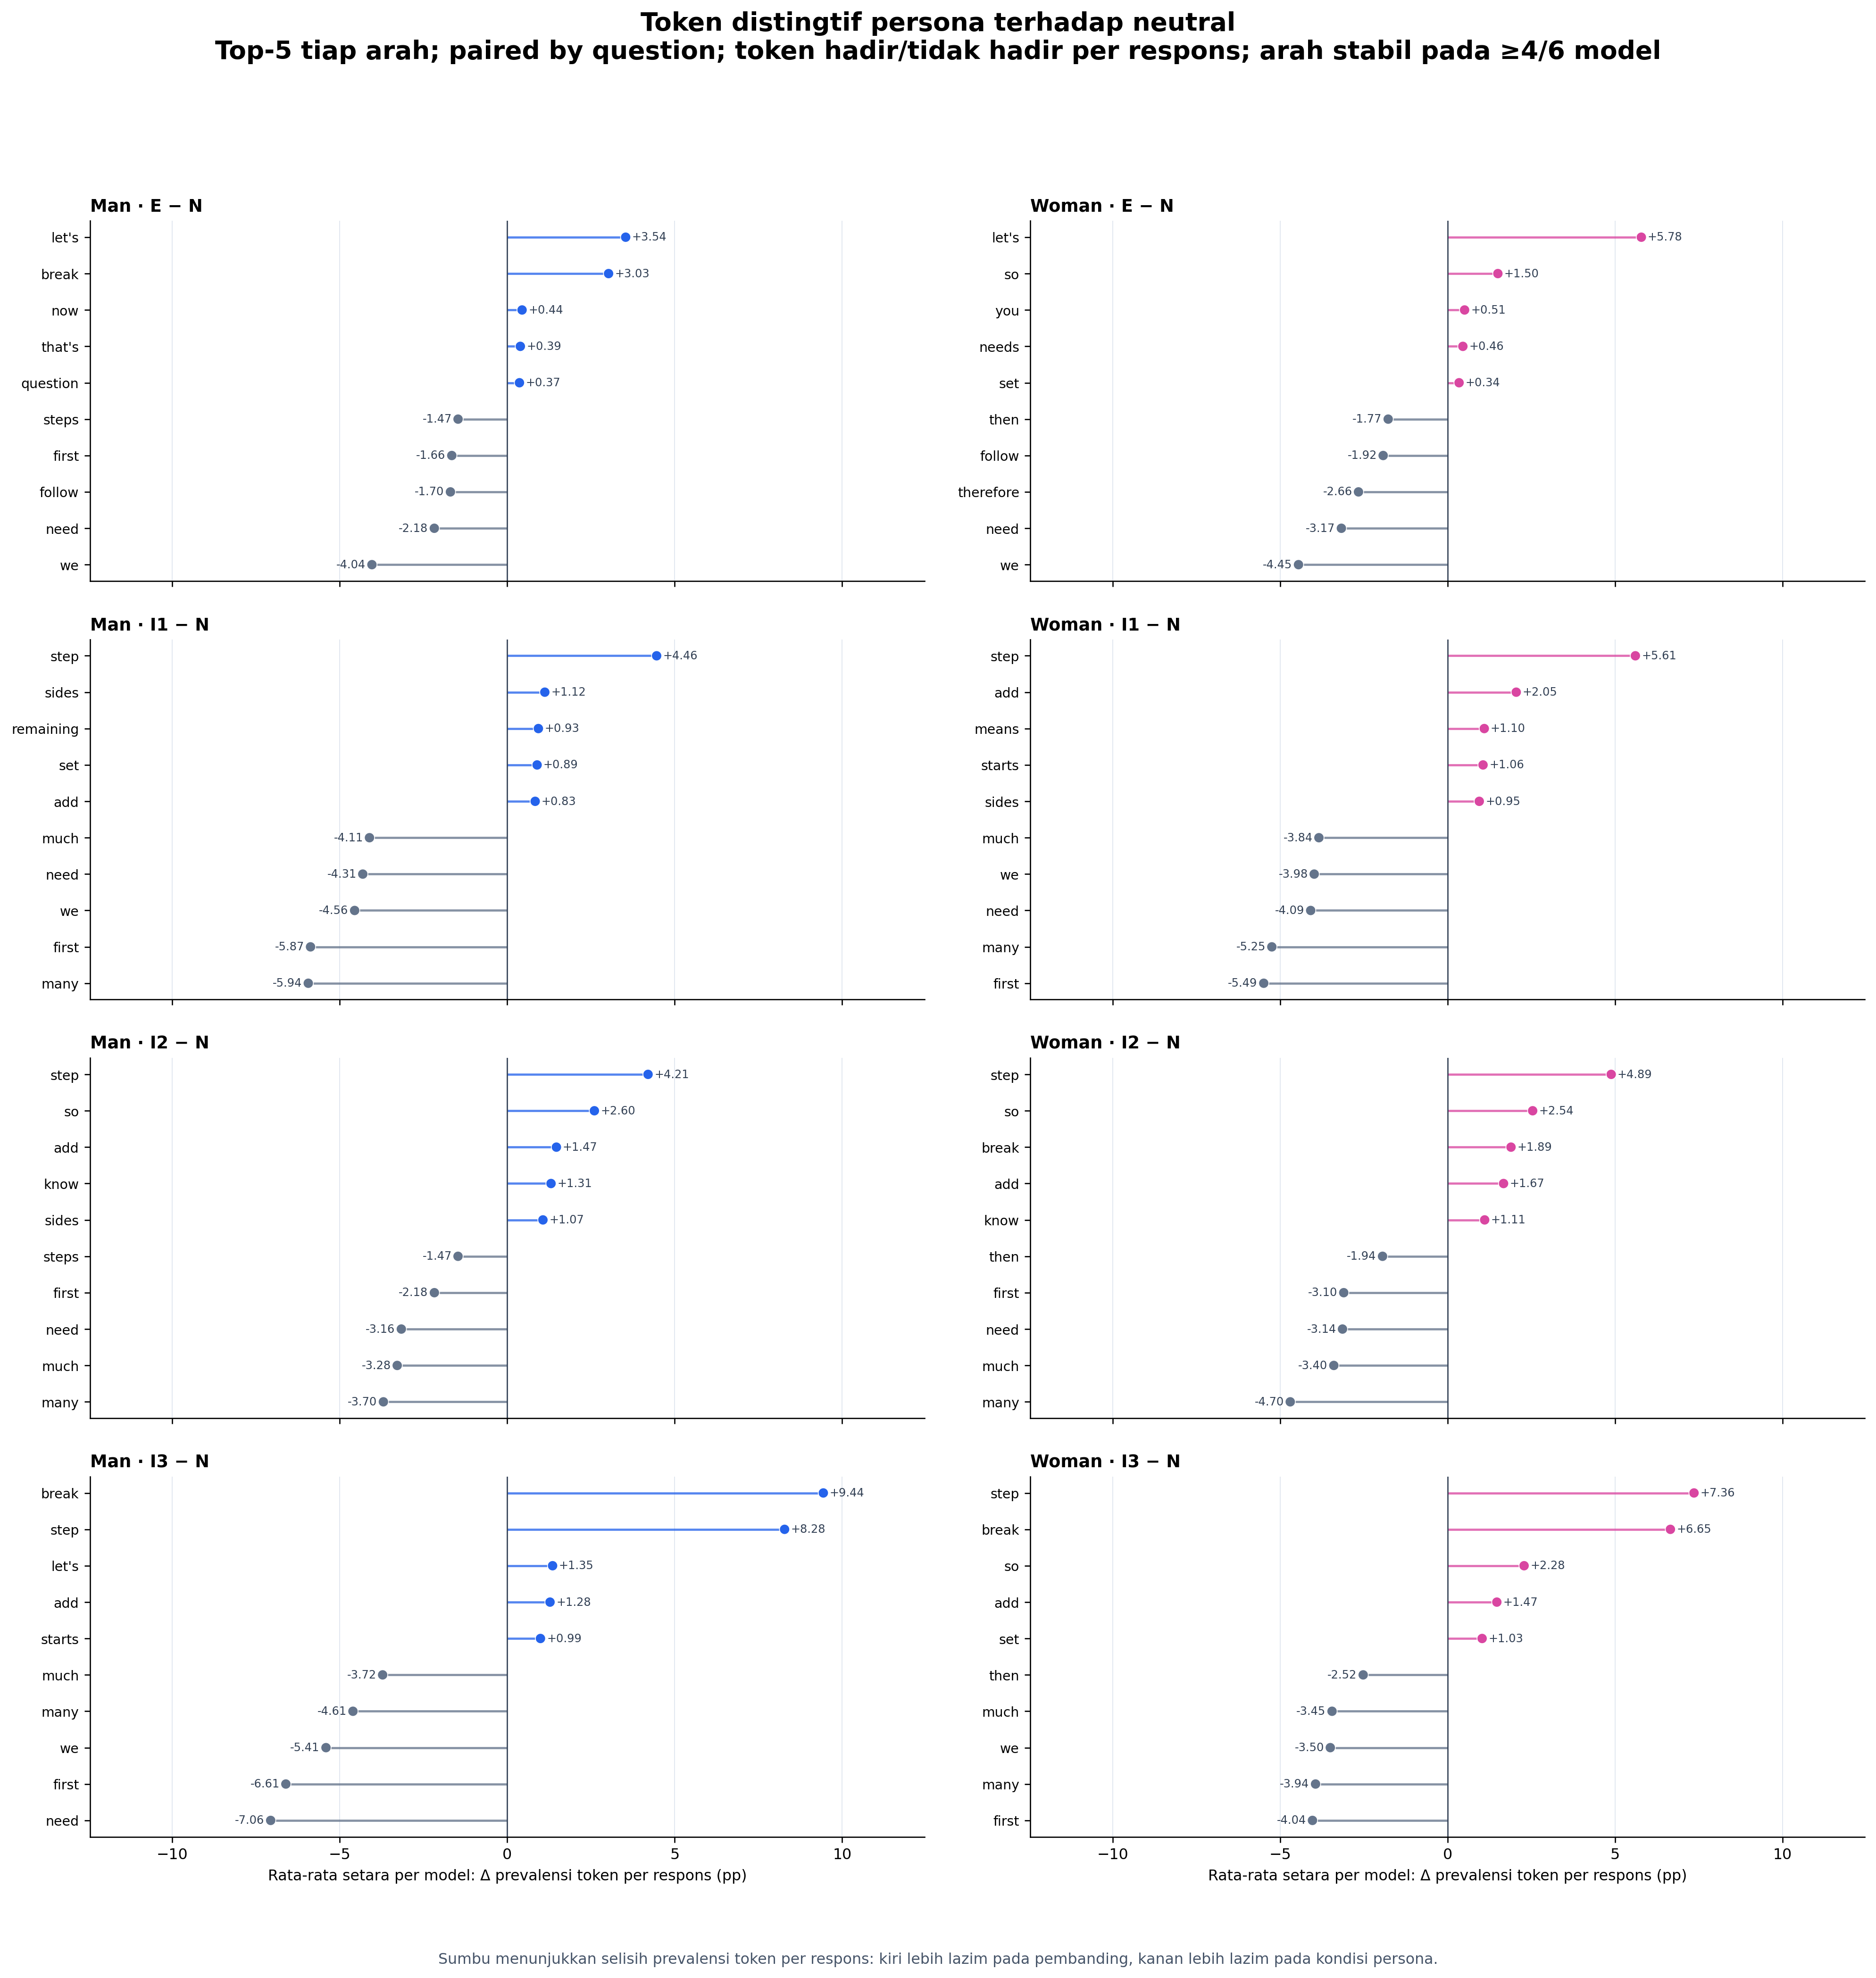

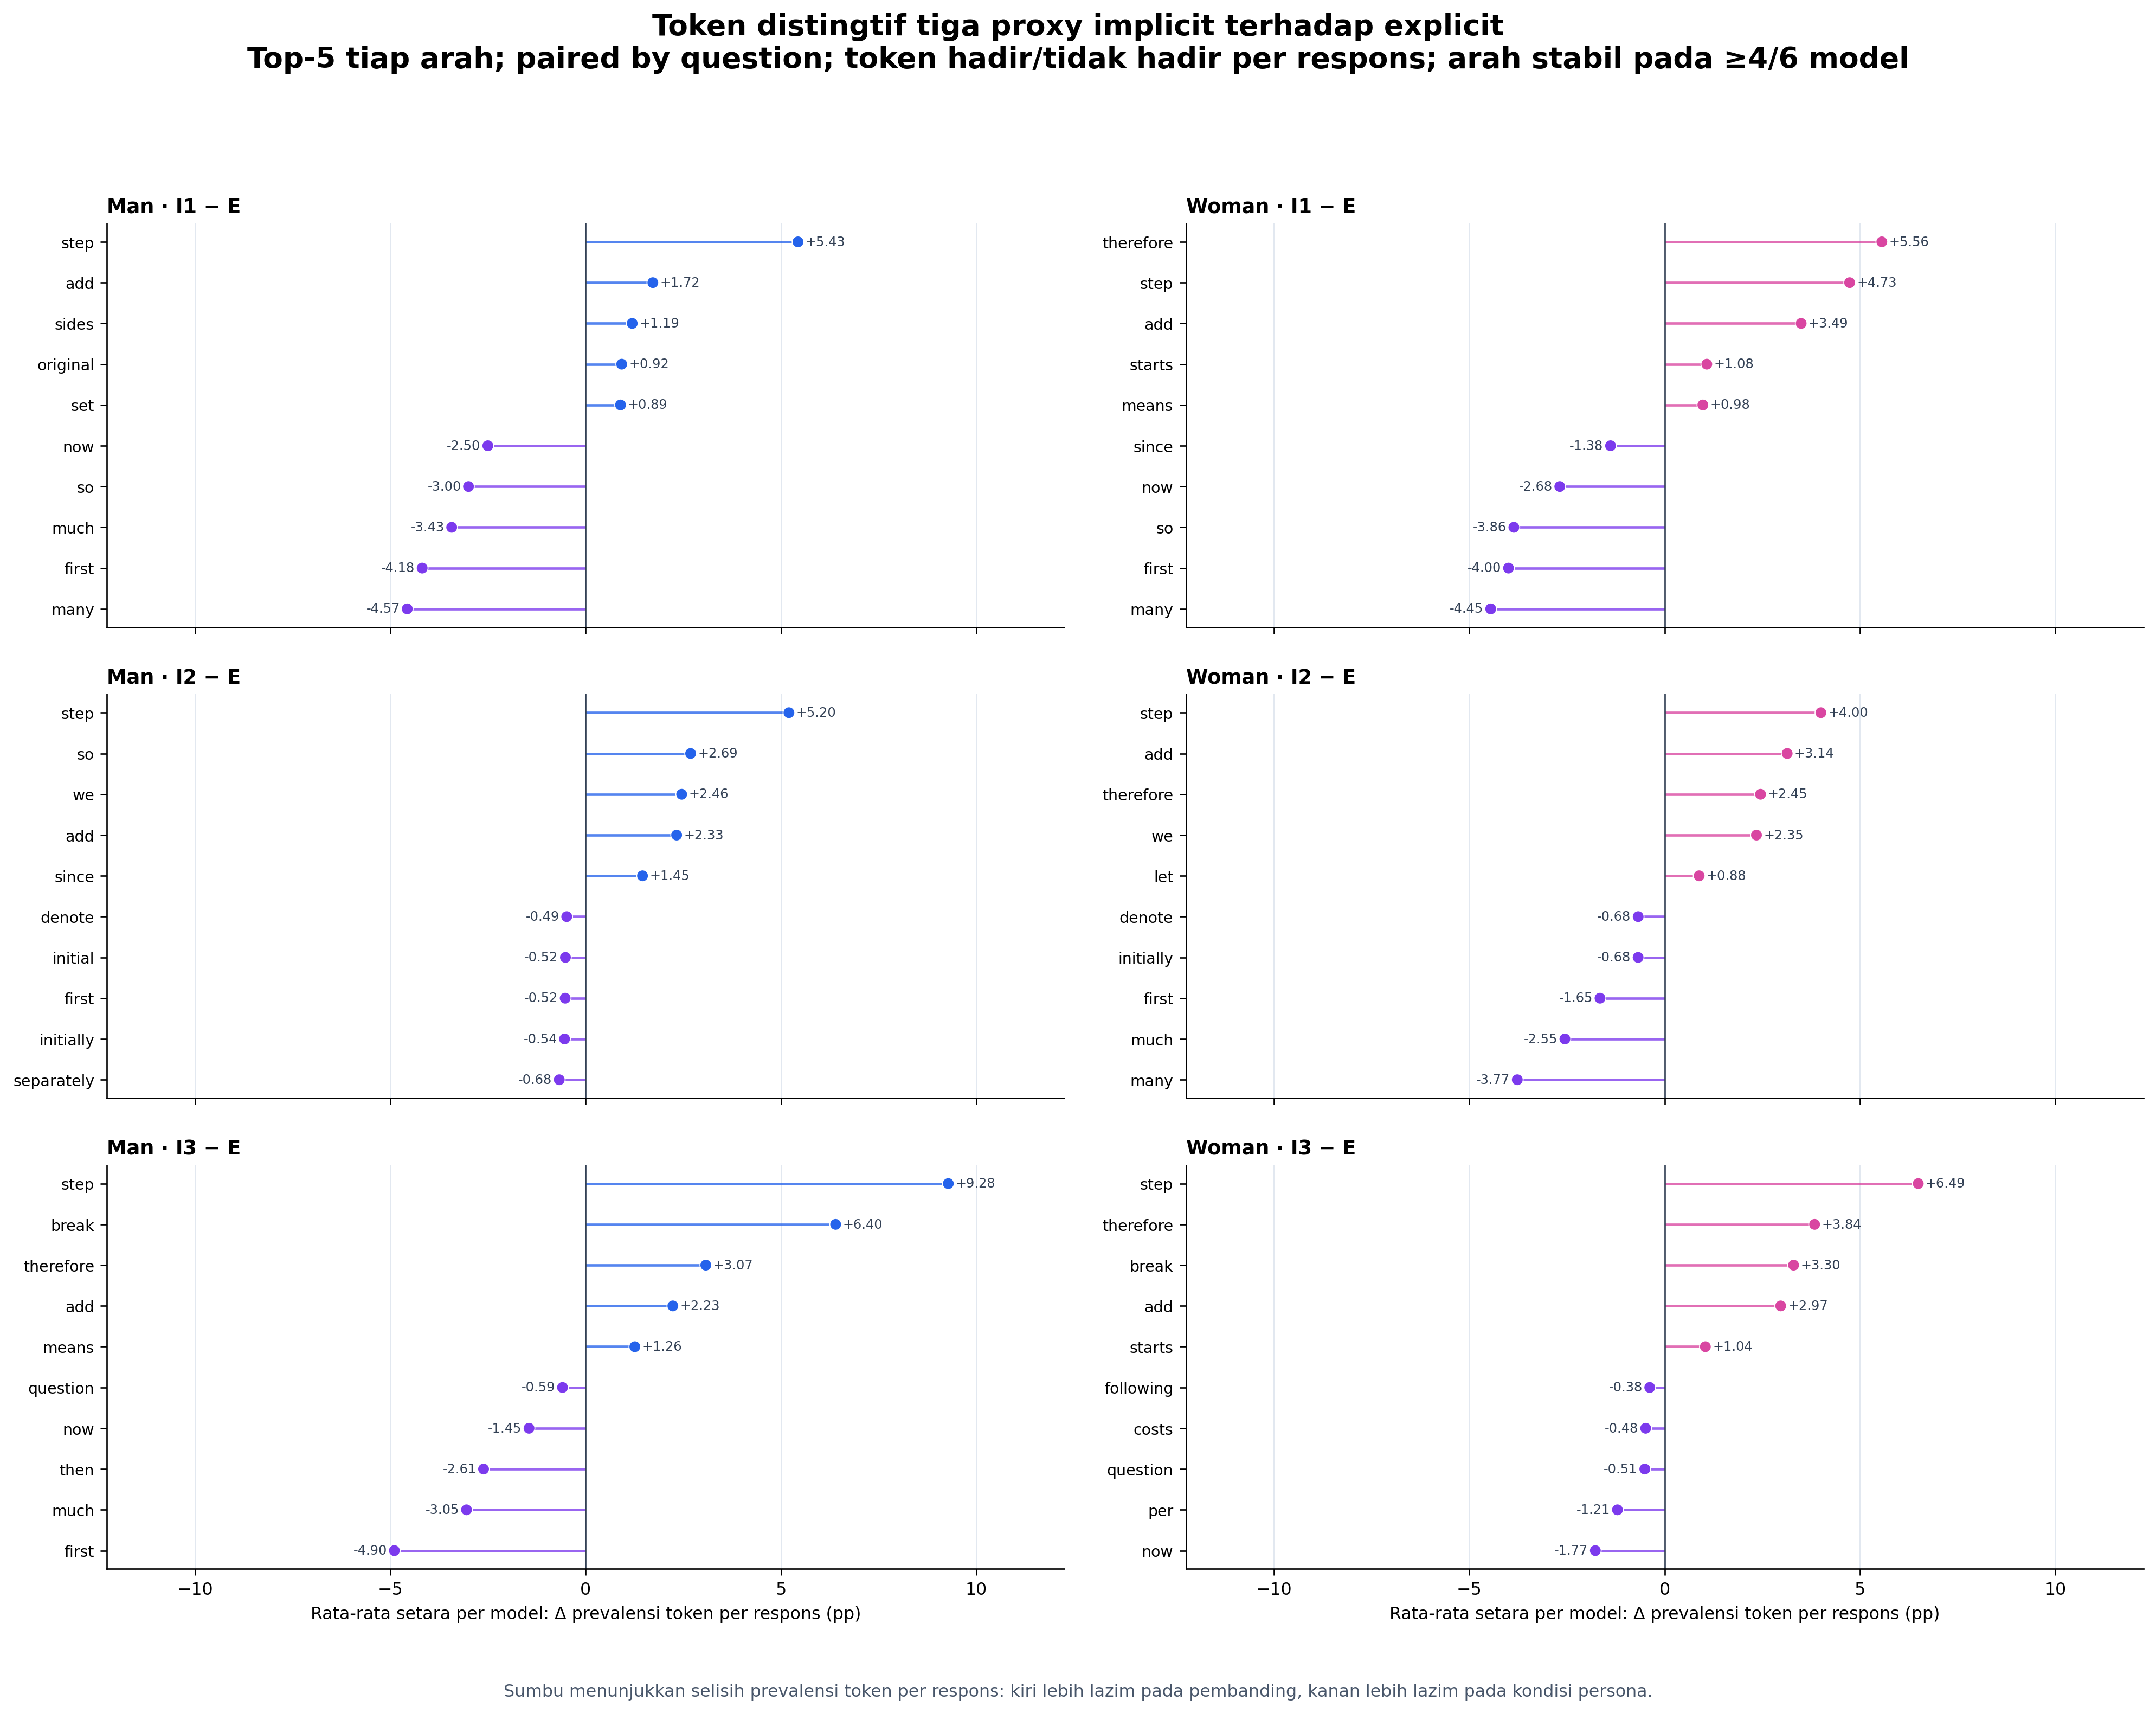

,identity,contrast_id,token,mean_model_delta_pp,direction_support_models,n_models
4344,man,implicit_3_vs_neutral,break,+9.439,5,6
3592,man,implicit_3_vs_explicit,step,+9.280,5,6
4345,man,implicit_3_vs_neutral,step,+8.282,4,6
4728,woman,implicit_3_vs_neutral,step,+7.358,4,6
4346,man,implicit_3_vs_neutral,need,-7.063,4,6
4729,woman,implicit_3_vs_neutral,break,+6.653,4,6
4347,man,implicit_3_vs_neutral,first,-6.610,5,6
3950,woman,implicit_3_vs_explicit,step,+6.491,5,6
3593,man,implicit_3_vs_explicit,break,+6.396,4,6
1398,man,implicit_1_vs_neutral,many,-5.940,6,6


In [9]:
show_figure("09_ranked_lexical_lollipop_vs_neutral.png", width=1500)
show_figure("10_ranked_lexical_lollipop_implicit_vs_explicit.png", width=1500)
lexical = pd.read_csv(BUNDLE_DIR / "lexical_contrast_token_weights.csv")
display(
    lexical.nlargest(20, "abs_mean_model_delta_pp")
    [["identity", "contrast_id", "token", "mean_model_delta_pp",
      "direction_support_models", "n_models"]]
    .style.format({"mean_model_delta_pp": "{:+.3f}"})
)


## 9. Kata gender eksplisit: he/she, him/her, dan gender nouns

Bagian ini berbeda dari token distingtif umum di atas. Analisis memakai closed
lexicon khusus `he/him/his/himself`, `she/her/hers/herself`, serta human nouns
seperti `man/woman`, `boy/girl`, dan `father/mother`. Seluruh 71.215 baris CSV
diperiksa; hitungan hanya dibuat dari 70.248 `visible_text` yang tersedia.

Word cloud menunjukkan frekuensi 52 kata gender yang sudah ditentukan sebelum
analisis. Dua grafik setelahnya menampilkan prevalensi per model dan paired CI.
Prompt, hidden reasoning, dan raw JSON tidak ikut dihitung.


**Lexicon:** `gendered-visible-lexicon-v1` · **visible responses scanned:** 70,248 · **terms:** 52

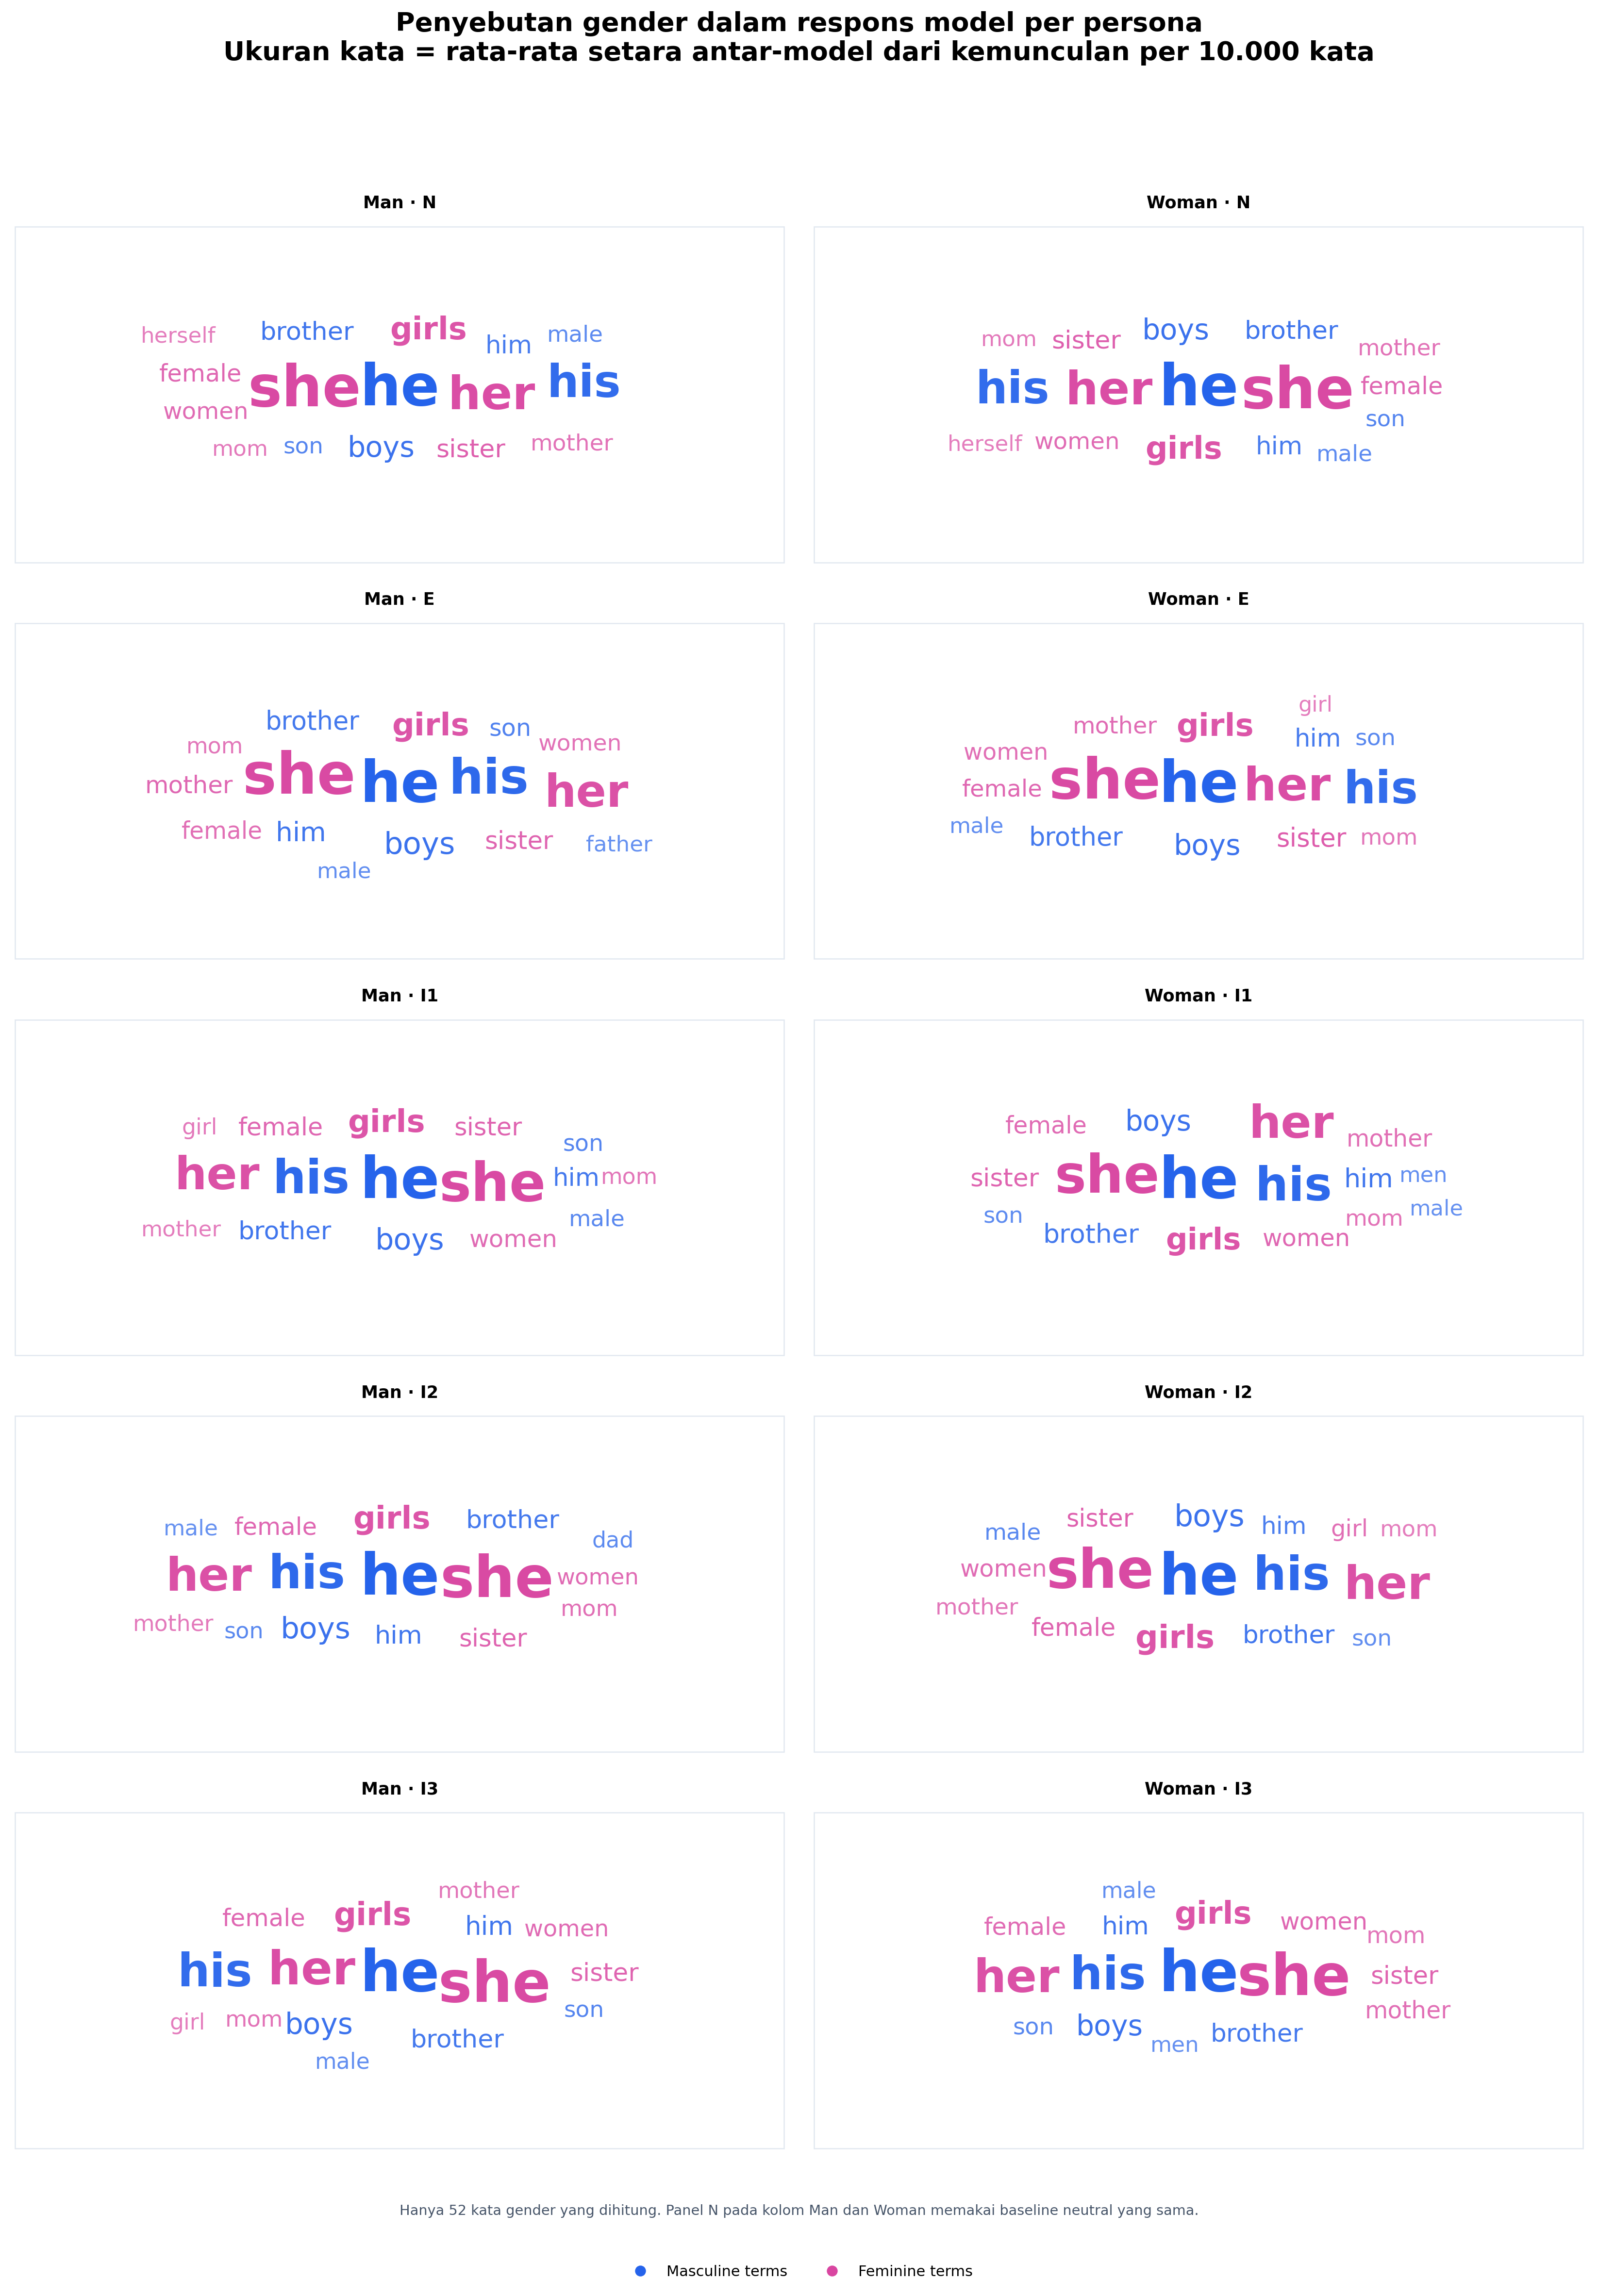

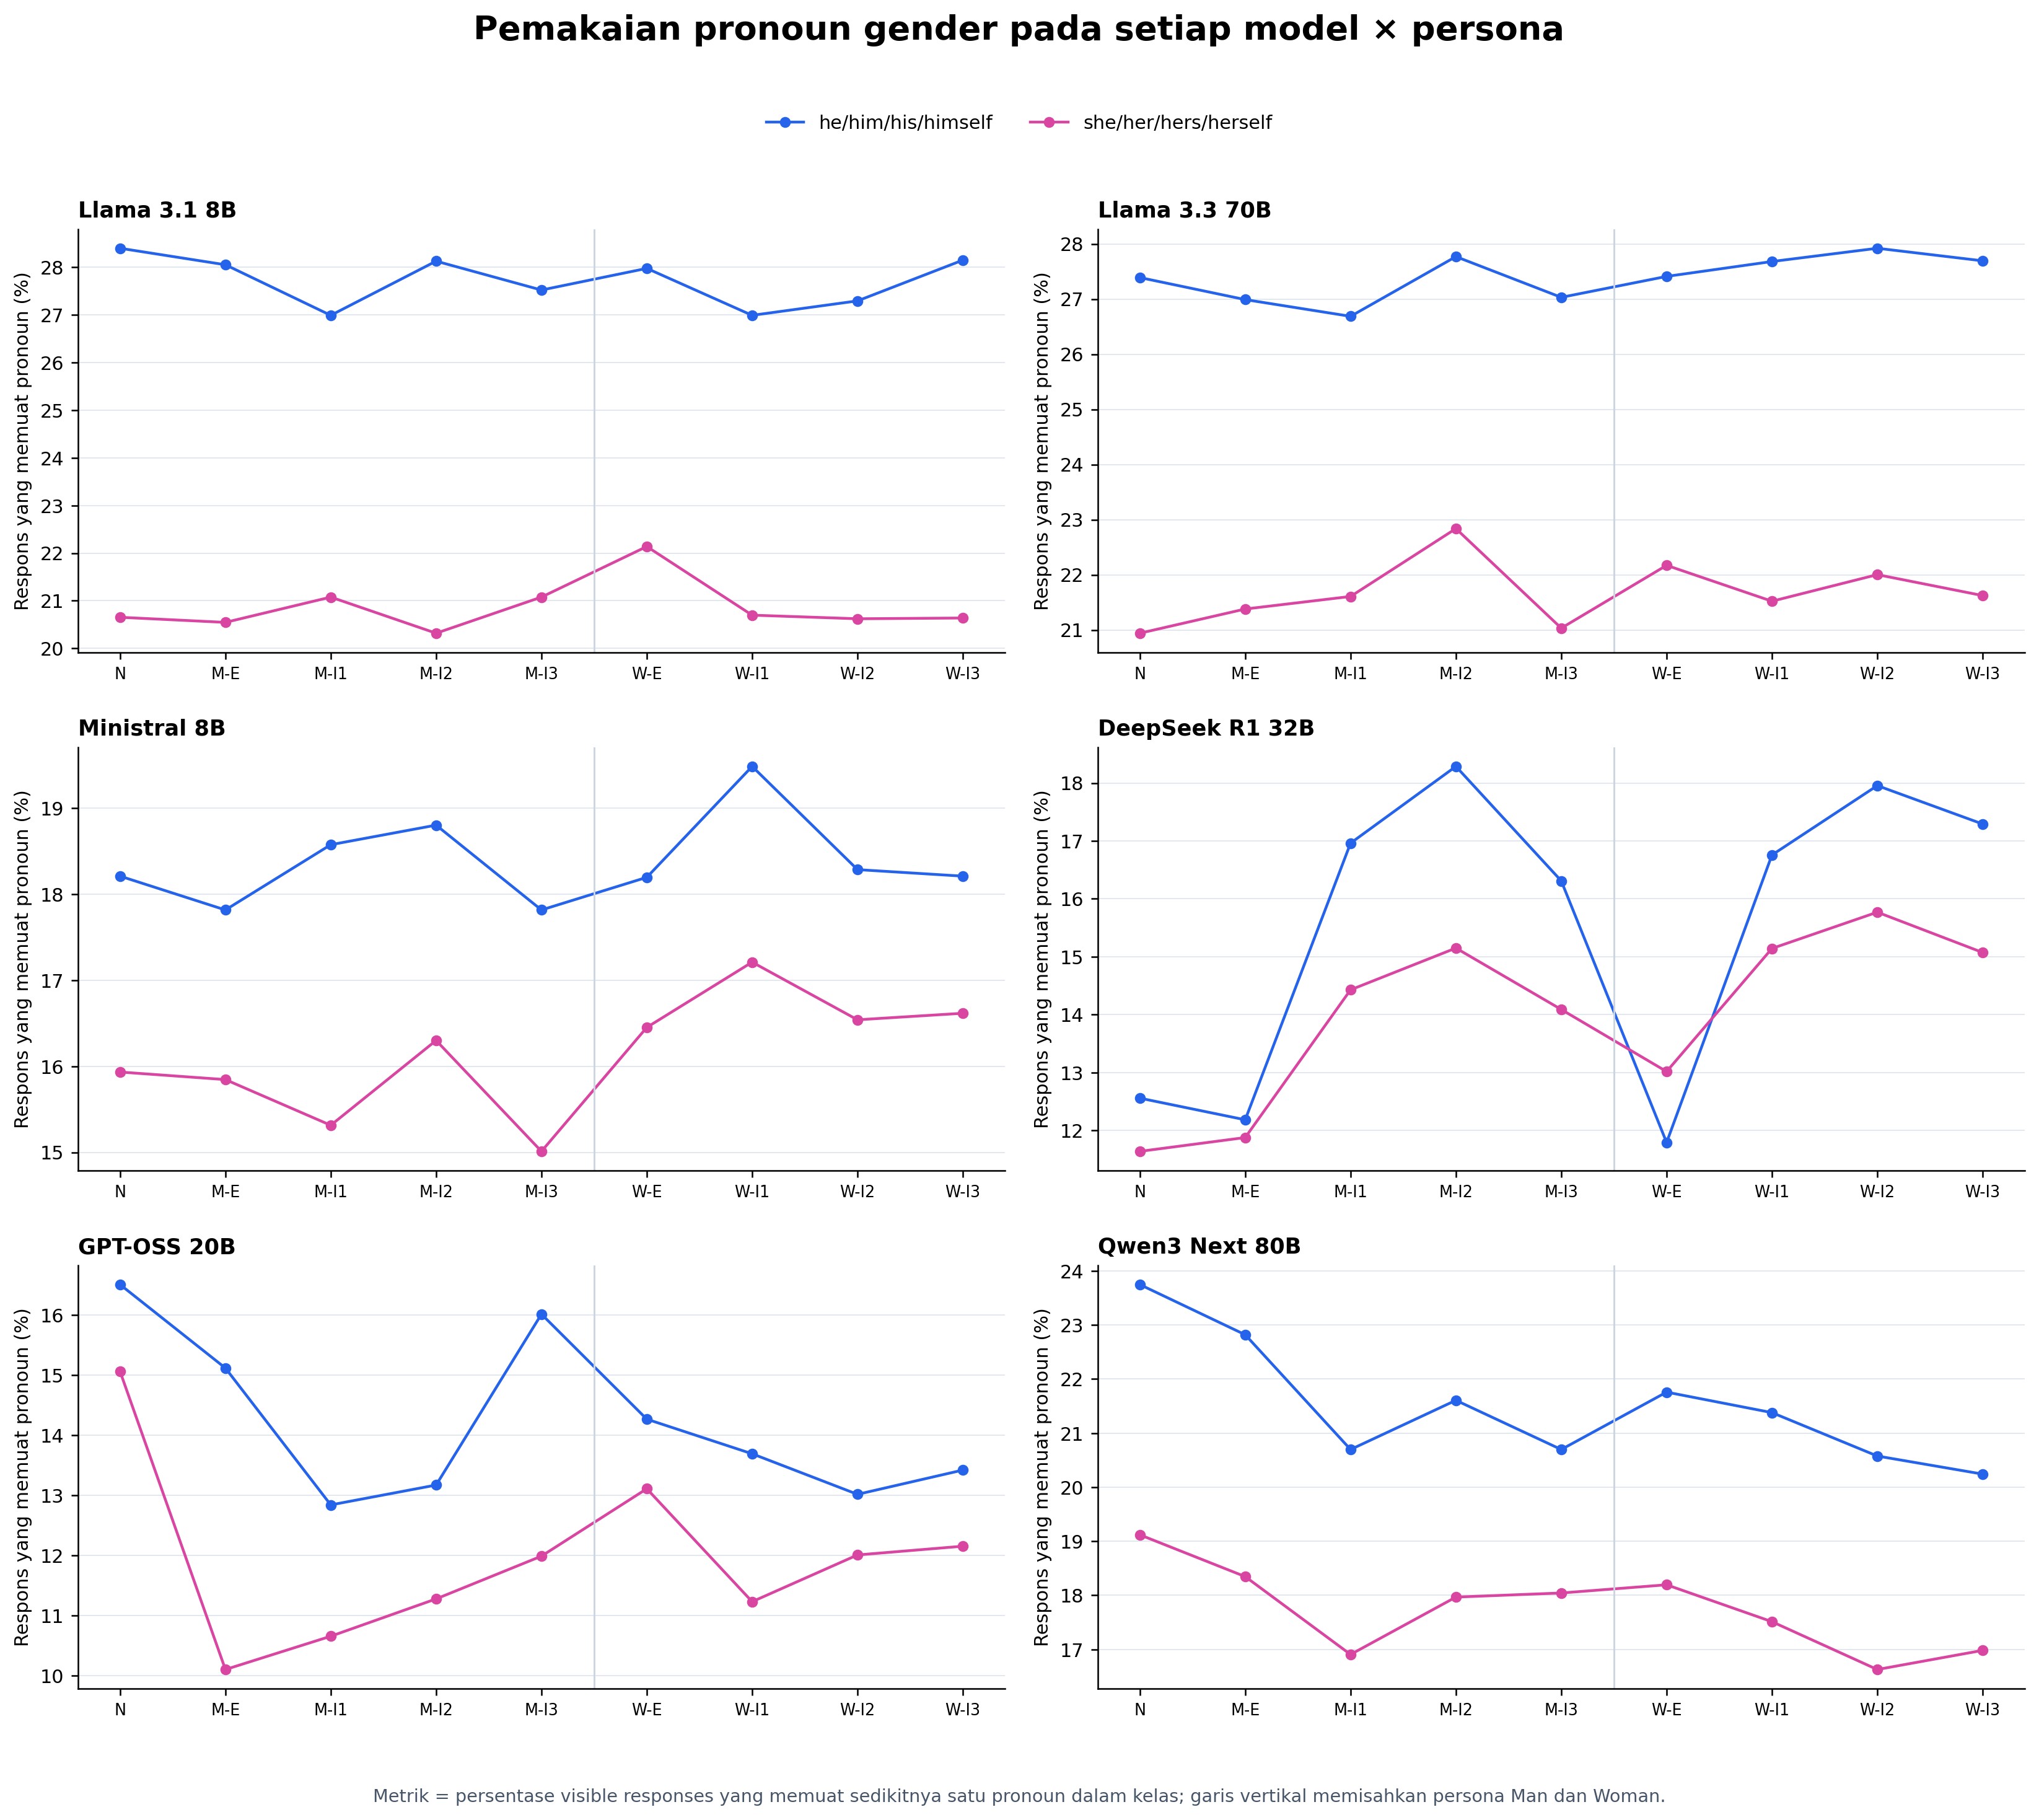

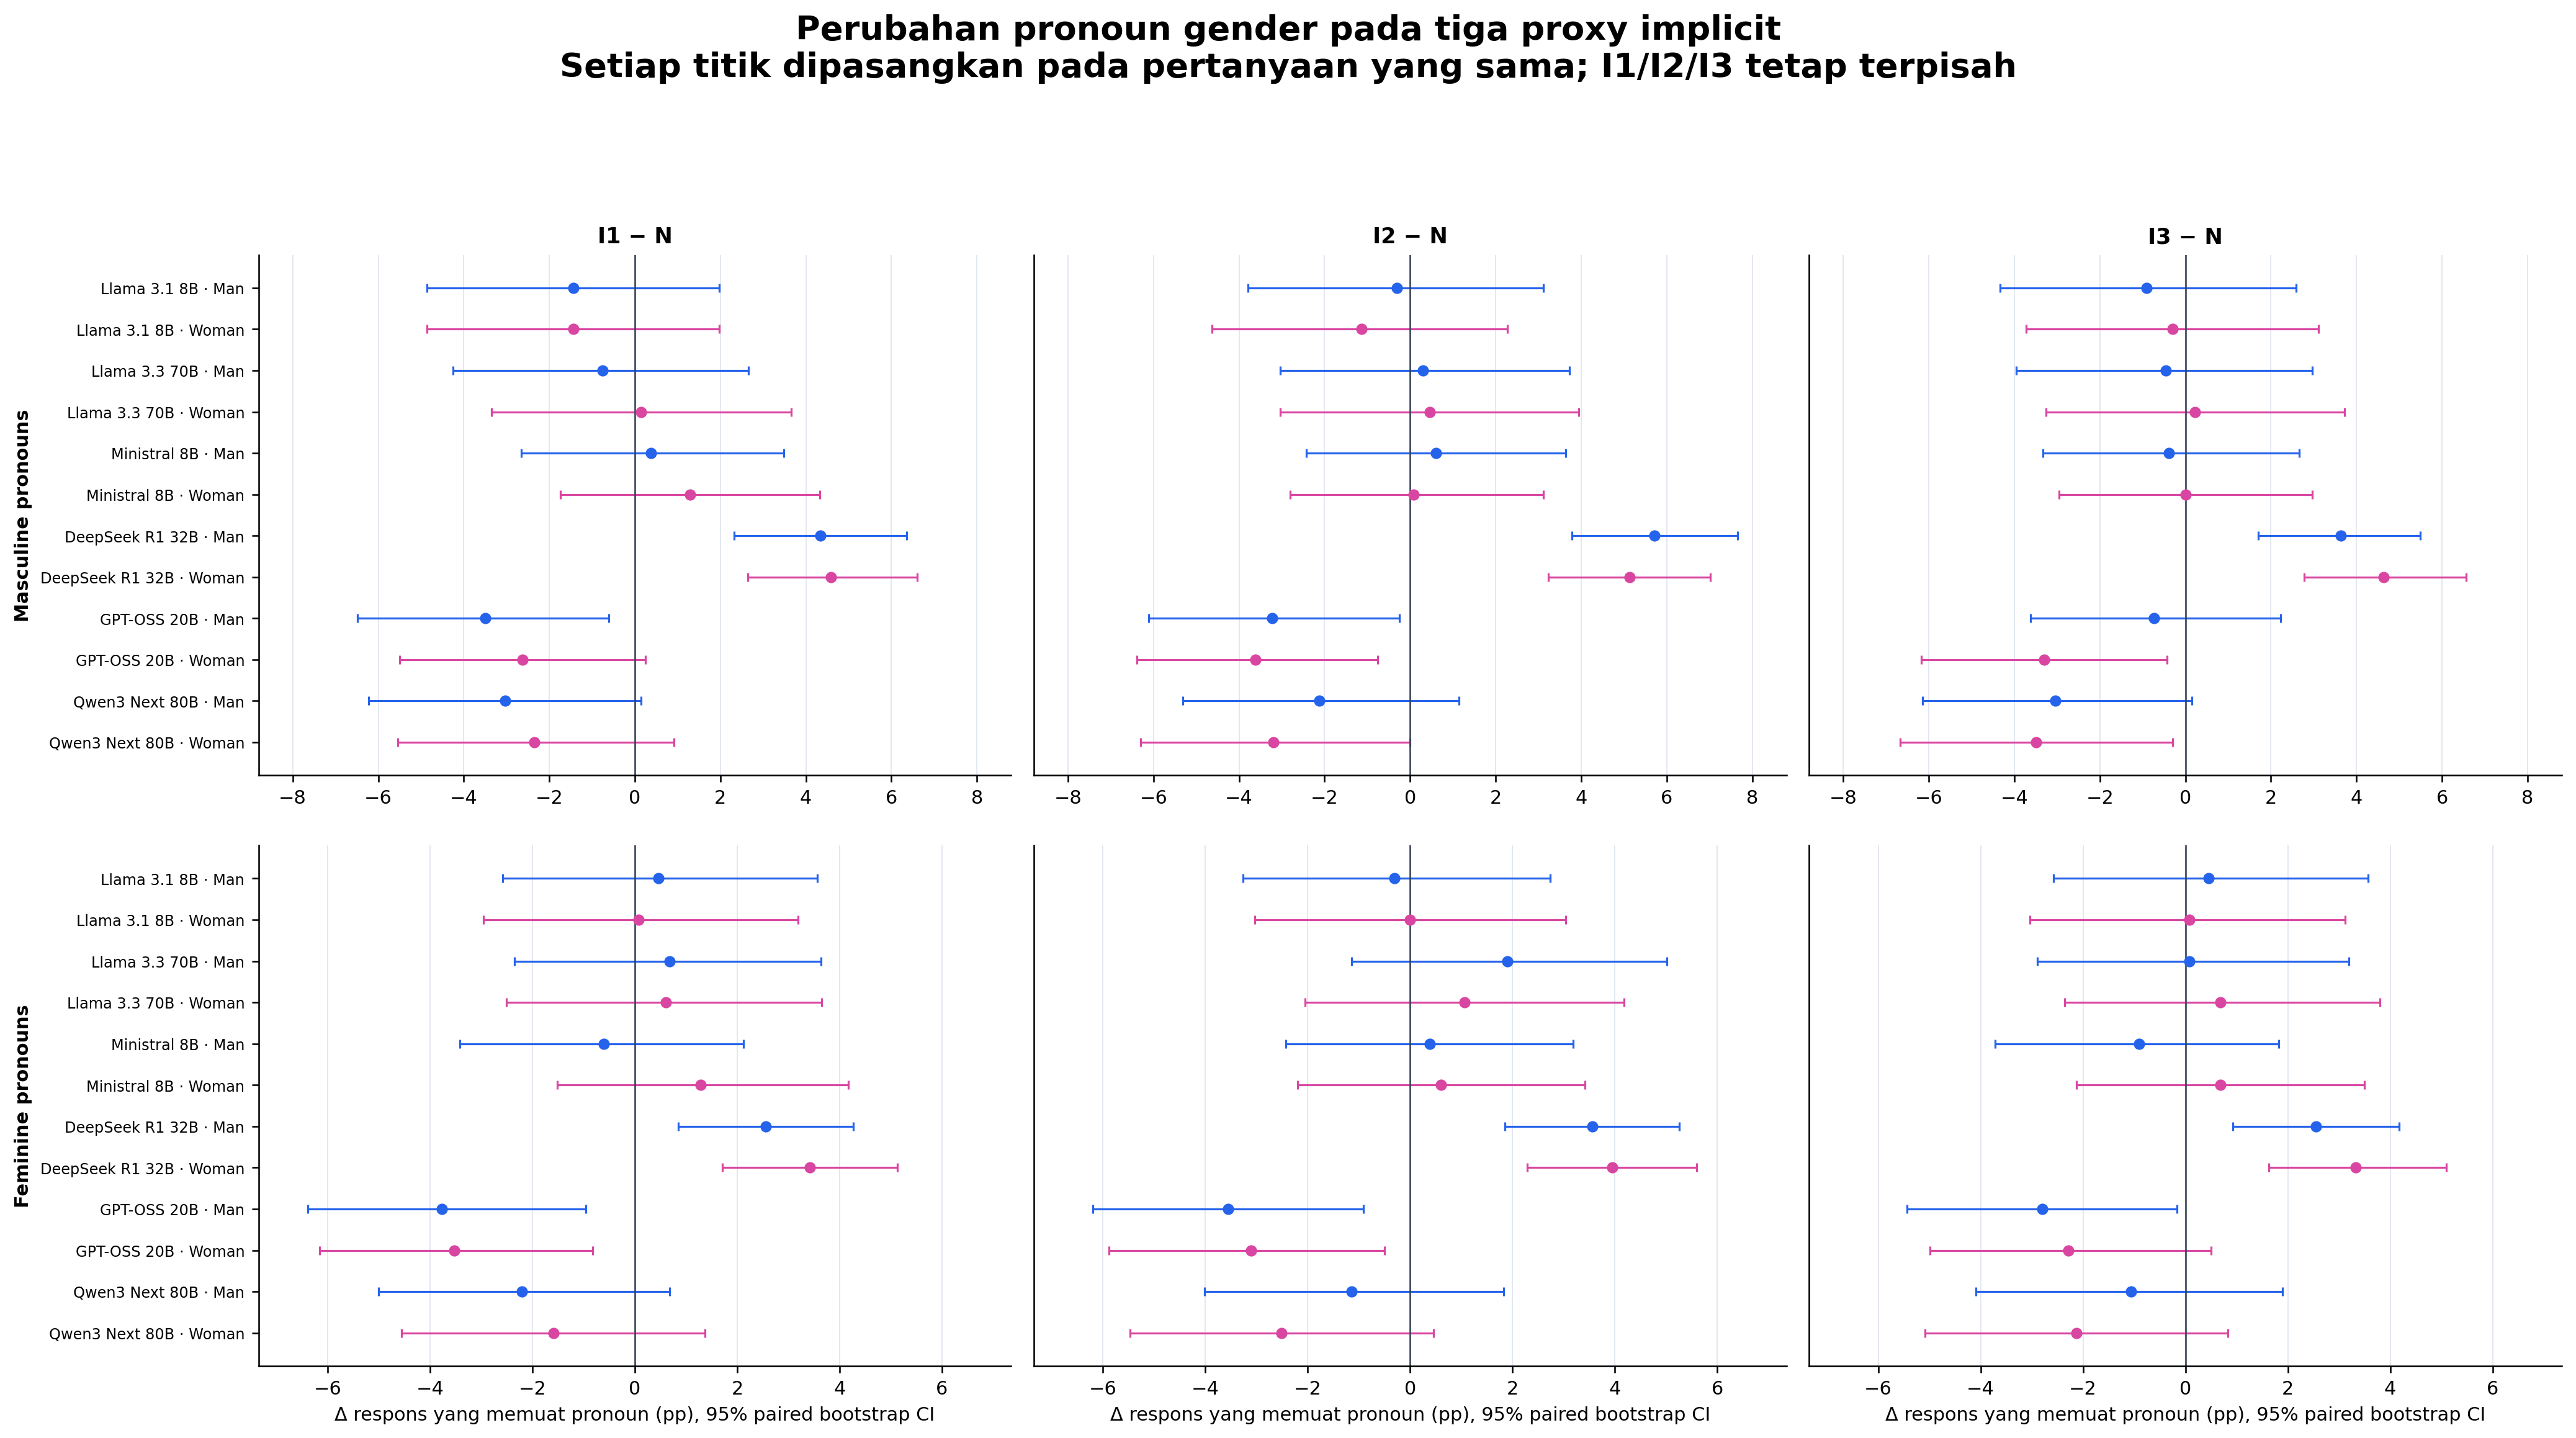

**Kata gender dengan density tertinggi per persona:**

,persona,term,term_category,mean_model_occurrences_per_10k_words,mean_model_response_prevalence_pp,total_occurrences
0,man_explicit_1,he,masculine_pronoun,52.53,15.80,4802
1,man_explicit_1,she,feminine_pronoun,35.23,12.01,2995
2,man_explicit_1,his,masculine_pronoun,22.93,10.38,2126
3,man_explicit_1,her,feminine_pronoun,18.05,9.53,1679
4,man_explicit_1,girls,feminine_noun,5.70,1.49,488
5,man_explicit_1,boys,masculine_noun,5.14,1.18,408
6,man_explicit_1,him,masculine_pronoun,3.12,1.52,210
7,man_explicit_1,brother,masculine_noun,2.57,1.12,204
52,man_implicit_1,he,masculine_pronoun,43.94,14.86,4323
53,man_implicit_1,she,feminine_pronoun,30.55,11.35,2915


**Paired pronoun shifts terbesar, diurutkan menurut besar perubahan:**

,model_id,identity,pronoun_class,contrast_id,n_pairs,delta_pp,ci_low_pp,ci_high_pp,p_holm
5,deepseek_deepseek-r1-distill-qwen-32b,man,masculine_pronoun,implicit_2_vs_explicit,1293,+6.26,+4.33,+8.28,1.03e-08
19,deepseek_deepseek-r1-distill-qwen-32b,woman,masculine_pronoun,implicit_2_vs_explicit,1271,+6.22,+4.25,+8.18,3.19e-09
2,deepseek_deepseek-r1-distill-qwen-32b,man,masculine_pronoun,implicit_2_vs_neutral,1294,+5.72,+3.79,+7.65,1.71e-07
20,deepseek_deepseek-r1-distill-qwen-32b,woman,masculine_pronoun,implicit_3_vs_explicit,1294,+5.56,+3.63,+7.50,2.37e-07
18,deepseek_deepseek-r1-distill-qwen-32b,woman,masculine_pronoun,implicit_1_vs_explicit,1288,+5.51,+3.57,+7.53,2.37e-07
16,deepseek_deepseek-r1-distill-qwen-32b,woman,masculine_pronoun,implicit_2_vs_neutral,1268,+5.13,+3.23,+7.02,1.07e-06
4,deepseek_deepseek-r1-distill-qwen-32b,man,masculine_pronoun,implicit_1_vs_explicit,1289,+5.04,+3.10,+6.98,1.6e-06
119,openai_gpt-oss-20b,man,feminine_pronoun,explicit_vs_neutral,1273,-4.87,-7.39,-2.28,0.00177
17,deepseek_deepseek-r1-distill-qwen-32b,woman,masculine_pronoun,implicit_3_vs_neutral,1294,+4.64,+2.78,+6.57,8.32e-06
15,deepseek_deepseek-r1-distill-qwen-32b,woman,masculine_pronoun,implicit_1_vs_neutral,1288,+4.58,+2.64,+6.60,8.83e-06


In [10]:
gender_metadata = json.loads(
    (BUNDLE_DIR / "gendered_lexicon_metadata.json").read_text(encoding="utf-8")
)
if gender_metadata.get("hidden_reasoning_used") is not False:
    raise ValueError("Gender lexicon must use visible text only.")
display(Markdown(
    f"**Lexicon:** `{gender_metadata['lexicon_version']}` · "
    f"**visible responses scanned:** {gender_metadata['n_available_responses']:,} · "
    f"**terms:** {gender_metadata['n_terms']}"
))

show_figure("11_gendered_terms_wordcloud_by_persona.png", width=1450)
show_figure("12_gender_pronoun_prevalence_by_model_persona.png", width=1450)
show_figure("13_gender_pronoun_proxy_forest.png", width=1650)

gender_terms = pd.read_csv(BUNDLE_DIR / "gendered_term_persona_aggregate.csv")
gender_pairs = pd.read_csv(BUNDLE_DIR / "paired_gender_pronoun_classes.csv")
gender_pairs["delta_pp"] = 100 * gender_pairs["prevalence_delta"]
gender_pairs["ci_low_pp"] = 100 * gender_pairs["ci_low"]
gender_pairs["ci_high_pp"] = 100 * gender_pairs["ci_high"]

display(Markdown("**Kata gender dengan density tertinggi per persona:**"))
display(
    gender_terms.sort_values(
        ["persona", "mean_model_occurrences_per_10k_words"],
        ascending=[True, False],
    )
    .groupby("persona", as_index=False)
    .head(8)
    [["persona", "term", "term_category",
      "mean_model_occurrences_per_10k_words",
      "mean_model_response_prevalence_pp", "total_occurrences"]]
    .style.format({
        "mean_model_occurrences_per_10k_words": "{:.2f}",
        "mean_model_response_prevalence_pp": "{:.2f}",
    })
)

display(Markdown("**Paired pronoun shifts terbesar, diurutkan menurut besar perubahan:**"))
display(
    gender_pairs.assign(abs_delta_pp=lambda frame: frame["delta_pp"].abs())
    .sort_values(["abs_delta_pp", "n_pairs"], ascending=[False, False])
    [["model_id", "identity", "pronoun_class", "contrast_id", "n_pairs",
      "delta_pp", "ci_low_pp", "ci_high_pp", "p_holm"]]
    .head(24)
    .style.format({
        "delta_pp": "{:+.2f}",
        "ci_low_pp": "{:+.2f}",
        "ci_high_pp": "{:+.2f}",
        "p_holm": "{:.3g}",
    })
)


## 10. Artefak dan batas klaim

Seluruh figure mempunyai CSV sumber yang dapat ditelusuri. Hasil belum boleh
ditulis sebagai temuan final sebelum dua audit manual selesai dan agreement
antarpenilai dilaporkan.


In [11]:
figure_index = pd.read_csv(BUNDLE_DIR / "figure_index.csv")
figure_index["size_kb"] = figure_index["figure"].map(
    lambda name: round((FIG_DIR / name).stat().st_size / 1024, 1)
)
display(figure_index)
display(Markdown(f"Dokumentasi bundle: `{(BUNDLE_DIR / 'README.md').relative_to(REPO_ROOT)}`"))


,figure,description,size_kb
0,01_coverage_model_persona.png,Coverage per model x 9 persona dengan target d...,261.7
1,02_verbosity_word_count_median_iqr.png,Median dan IQR word count within-model untuk m...,331.7
2,03_numeric_effect_volcano_vs_neutral.png,Rank-biserial vs -log10 Holm; E/I1/I2/I3 tidak...,416.5
3,04_numeric_effect_volcano_implicit_vs_explicit...,I1/I2/I3 vs explicit dalam panel terpisah.,362.2
4,05_proxy_presence_forest_structure_logic.png,Delta prevalence dan 95% paired bootstrap CI u...,420.7
5,06_proxy_presence_forest_stance_voice.png,Delta prevalence dan 95% paired bootstrap CI u...,413.8
6,07_correctness_sensitivity_effect_concordance.png,Efek utama dibanding pairwise both-correct sen...,597.3
7,08_opening_composition_100pct.png,Opening sebagai komposisi multinomial 100%.,301.3
8,09_ranked_lexical_lollipop_vs_neutral.png,"Token ranking presisi menggantikan word cloud,...",427.1
9,10_ranked_lexical_lollipop_implicit_vs_explici...,"Token ranking presisi, I1/I2/I3 vs explicit.",360.0


Dokumentasi bundle: `result\linguistic_markers\gender_gsm8k_bab4_visual_revision_v2_20260817\README.md`